# R7 - Fase 0: Diagnóstico de la configuración basal ConvNeXt-Tiny-A

Este notebook es **exclusivamente diagnóstico**. Describe el comportamiento del entrenamiento y de las predicciones de ConvNeXt-Tiny con la imagen ecográfica completa (representación A), seleccionada en R6 por mayor Average Precision (AP) medio en `validation` (semillas 42, 43 y 44), con el fin de identificar problemas observables que permitan justificar, en fases posteriores, las técnicas de optimización de R7.

## 1. Configuración y fuentes

Se localiza la raíz del proyecto, se definen las rutas de entrada y la carpeta de salida.

In [1]:
from pathlib import Path
import itertools
import json
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score


def locate_project_root() -> Path:
    current_dir = Path.cwd().resolve()

    for candidate in [current_dir, *current_dir.parents]:
        if (candidate / "src").exists() and (candidate / "data").exists():
            return candidate

    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


PROJECT_ROOT = locate_project_root()
print("Raíz del proyecto:", PROJECT_ROOT)

Raíz del proyecto: /home/jvillanueva/projects/ovarian-tumor-ultrasound-classification


In [2]:
ARCH = "convnext_tiny"
CONDITION = "A"
SEEDS = [42, 43, 44]
THRESHOLD = 0.5  # umbral fijo de R6

N_VALIDATION = 200
N_MALIGNANT = 22
N_BENIGN = 178
PREVALENCE = N_MALIGNANT / N_VALIDATION

CLASSIFICATION_DIR = PROJECT_ROOT / "results" / "classification"
RUNS_DIR = CLASSIFICATION_DIR / "r4_benchmark" / ARCH / CONDITION
R6_SELECTION_JSON = CLASSIFICATION_DIR / "r6_model_selection" / "r6_selection.json"
SPLIT_MANIFEST = PROJECT_ROOT / "configs" / "splits" / "mmotu_experimental_split_standard.csv"

OUTPUT_DIR = CLASSIFICATION_DIR / "r7_optimizacion" / "diagnostico_baseline"
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR = OUTPUT_DIR / "figures"
FILE_PREFIX = "r7_diag"

SEED_COLORS = {42: "#332288", 43: "#117733", 44: "#AA4499"}
CLASS_COLORS = {0: "#0072B2", 1: "#D55E00"}
CLASS_NAMES = {0: "Benigna (0)", 1: "Maligna (1)"}

plt.rcParams.update(
    {
        "figure.dpi": 100,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
    }
)

OUTPUT_REGISTRY = []


def _checked_output_path(path) -> Path:
    path = Path(path).resolve()
    if not path.is_relative_to(OUTPUT_DIR.resolve()):
        raise ValueError(f"Escritura fuera de la carpeta de salidas de R7: {path}")
    return path


def _register(path: Path) -> None:
    relative = path.relative_to(PROJECT_ROOT.resolve()).as_posix()
    if relative not in OUTPUT_REGISTRY:
        OUTPUT_REGISTRY.append(relative)


def save_table(df: pd.DataFrame, name: str, index: bool = False) -> Path:
    path = _checked_output_path(TABLES_DIR / f"{FILE_PREFIX}_{name}.csv")
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=index, encoding="utf-8")
    _register(path)
    return path


def save_figure(fig, name: str) -> Path:
    path = _checked_output_path(FIGURES_DIR / f"{FILE_PREFIX}_{name}.png")
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    _register(path)
    return path


def by_seed(values, nd=3) -> str:
    return " · ".join(f"{seed}: {float(values[seed]):.{nd}f}" for seed in SEEDS)


print("Entradas (solo lectura):", RUNS_DIR.relative_to(PROJECT_ROOT).as_posix())
print("Salidas:                ", OUTPUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Entradas (solo lectura): results/classification/r4_benchmark/convnext_tiny/A
Salidas:                 results/classification/r7_optimizacion/diagnostico_baseline


In [3]:
def run_dir(seed: int) -> Path:
    return RUNS_DIR / f"seed_{seed}"


JSON_FILES = ["run_config.json", "training_history.json", "validation_metrics.json", "best_auc_meta.json"]
PREDICTIONS_FILE = "val_predictions_best_auc.csv"
CHECKPOINT_FILE = "best_auc.pth"  # solo se comprueba su existencia; no se carga

missing = [
    run_dir(seed) / name
    for seed in SEEDS
    for name in [*JSON_FILES, PREDICTIONS_FILE, CHECKPOINT_FILE]
    if not (run_dir(seed) / name).exists()
]
for path in [R6_SELECTION_JSON, SPLIT_MANIFEST]:
    if not path.exists():
        missing.append(path)

if missing:
    raise FileNotFoundError("Faltan artefactos requeridos:\n" + "\n".join(str(p) for p in missing))

SOURCE_PATHS = [run_dir(seed) / name for seed in SEEDS for name in [*JSON_FILES, PREDICTIONS_FILE]]
SOURCE_PATHS += [R6_SELECTION_JSON, SPLIT_MANIFEST]


def read_json(path: Path) -> dict:
    with open(path, encoding="utf-8") as handle:
        return json.load(handle)


run_configs = {seed: read_json(run_dir(seed) / "run_config.json") for seed in SEEDS}
histories = {seed: read_json(run_dir(seed) / "training_history.json") for seed in SEEDS}
saved_metrics = {seed: read_json(run_dir(seed) / "validation_metrics.json") for seed in SEEDS}
best_meta = {seed: read_json(run_dir(seed) / "best_auc_meta.json") for seed in SEEDS}
predictions = {seed: pd.read_csv(run_dir(seed) / PREDICTIONS_FILE) for seed in SEEDS}
r6_selection = read_json(R6_SELECTION_JSON)

manifest = pd.read_csv(SPLIT_MANIFEST)
validation_manifest = manifest[manifest["experimental_split"] == "validation"].set_index("image_id")

print("Artefactos de las semillas", SEEDS, "leídos correctamente.")
print("Imágenes de validation en el manifiesto:", len(validation_manifest))

Artefactos de las semillas [42, 43, 44] leídos correctamente.
Imágenes de validation en el manifiesto: 200


## 2. Verificación de las ejecuciones basales

Se comprueba, para las semillas 42, 43 y 44

In [4]:
EXPECTED_PROTOCOL = {
    "experiment": "r4_benchmark",
    "architecture": ARCH,
    "condition": CONDITION,
    "seed_source": "cli_override",
    "csv_path": "configs/splits/mmotu_experimental_split_standard.csv",
    "image_dir": "data/processed/MMOTU_OTU_2D_experimental",
    "train_samples": 800,
    "validation_samples": N_VALIDATION,
    "pretrained": True,
    "freeze_backbone": False,
    "num_classes": 2,
    "batch_size": 32,
    "epochs_max": 30,
    "learning_rate_source": "yaml",
    "optimizer": "AdamW",
    "use_amp": True,
    "patience": 5,
    "threshold": THRESHOLD,
    "scheduler": None,
    "checkpoint_criterion": "max val_roc_auc (first epoch among ties)",
    "checkpoint_file": CHECKPOINT_FILE,
    "early_stopping_criterion": "val_weighted_loss (patience=5, min_delta=0.001)",
    "val_predictions": PREDICTIONS_FILE,
}
EXPECTED_FLOATS = {"learning_rate": 1e-4, "weight_decay": 1e-4, "min_delta": 1e-3}

for seed, config in run_configs.items():
    assert config["seed"] == seed, seed
    for key, expected in EXPECTED_PROTOCOL.items():
        assert config.get(key) == expected, (seed, key, config.get(key), expected)
    for key, expected in EXPECTED_FLOATS.items():
        assert abs(config[key] - expected) < 1e-12, (seed, key, config[key], expected)
    assert config["class_weights"] == run_configs[SEEDS[0]]["class_weights"], seed

assert np.allclose(run_configs[SEEDS[0]]["class_weights"], [0.5610, 4.5977], atol=1e-4)
assert all(set(run_configs[s]) == set(run_configs[SEEDS[0]]) for s in SEEDS)

print("Protocolo de R4 verificado en las 3 semillas.")
print("Pesos de clase (benigna, maligna):", run_configs[SEEDS[0]]["class_weights"])

Protocolo de R4 verificado en las 3 semillas.
Pesos de clase (benigna, maligna): [0.5610098242759705, 4.597701072692871]


### 2.1 Comparación de las configuraciones de entrenamiento

In [5]:
def _display_value(value):
    return json.dumps(value) if isinstance(value, (list, dict)) else value


config_rows = []
for key in run_configs[SEEDS[0]]:
    values = [run_configs[seed][key] for seed in SEEDS]
    config_rows.append(
        {
            "campo": key,
            **{f"seed_{seed}": _display_value(value) for seed, value in zip(SEEDS, values)},
            "constante_entre_semillas": len({json.dumps(v, sort_keys=True) for v in values}) == 1,
        }
    )

config_table = pd.DataFrame(config_rows)
save_table(config_table, "t1_config_comparada")

n_constant = int(config_table["constante_entre_semillas"].sum())
print(f"Campos constantes entre semillas: {n_constant} de {len(config_table)}")
print("Campos que difieren entre semillas:")
display(config_table.loc[~config_table["constante_entre_semillas"]].reset_index(drop=True))

Campos constantes entre semillas: 29 de 37
Campos que difieren entre semillas:


,campo,seed_42,seed_43,seed_44,constante_entre_semillas
0,seed,42,43,44,False
1,epochs_run,13,8,8,False
2,epoch_best,8,7,7,False
3,val_weighted_loss_at_best_checkpoint,0.432149,1.142077,1.247778,False
4,val_unweighted_loss_at_best_checkpoint,0.413707,0.321995,0.321712,False
5,val_acc_at_best_checkpoint,0.775,0.905,0.915,False
6,early_stopped_at_epoch,13,8,8,False
7,val_roc_auc_best,0.885342,0.829162,0.815628,False


### 2.2 Integridad de las predicciones y métricas recalculadas

Se contiene únicamente las probabilidades del **checkpoint seleccionado** (una sola época por semilla), no las de todas las épocas. Por ello, se recalculan ROC-AUC, AP, sensibilidad, especificidad, precisión y matriz de confusión con umbral 0.5 y se contrastan con `validation_metrics.json`.

In [6]:
EXPECTED_PREDICTION_COLUMNS = ["epoch", "image_id", "y_true", "probability_malignant"]

assert len(validation_manifest) == N_VALIDATION
assert int(validation_manifest["binary_label"].sum()) == N_MALIGNANT
assert ((validation_manifest["binary_class"] == "malignant") == (validation_manifest["binary_label"] == 1)).all()

reference_ids = None
for seed in SEEDS:
    df = predictions[seed]
    assert list(df.columns) == EXPECTED_PREDICTION_COLUMNS, seed
    assert len(df) == N_VALIDATION and df["image_id"].is_unique, seed
    assert df["epoch"].nunique() == 1 and int(df["epoch"].iloc[0]) == run_configs[seed]["epoch_best"], seed
    assert int(df["y_true"].sum()) == N_MALIGNANT, seed
    assert df["probability_malignant"].between(0, 1).all(), seed
    # Todas las imágenes pertenecen a validation (por tanto, ninguna es de test) y sus etiquetas coinciden con el manifiesto
    assert df["image_id"].isin(validation_manifest.index).all(), seed
    manifest_labels = validation_manifest.loc[df["image_id"], "binary_label"].to_numpy()
    assert (df["y_true"].to_numpy() == manifest_labels).all(), seed
    if reference_ids is None:
        reference_ids = df["image_id"].tolist()
    assert df["image_id"].tolist() == reference_ids, f"Orden de imágenes distinto en la semilla {seed}"

print("Predicciones: 200 imágenes de validation (22 malignas) por semilla, mismas imágenes y mismo orden en las 3 semillas.")

Predicciones: 200 imágenes de validation (22 malignas) por semilla, mismas imágenes y mismo orden en las 3 semillas.


In [7]:
def compute_metrics(y_true, y_prob, threshold=THRESHOLD):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    y_pred = (y_prob >= threshold).astype(int)

    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    tp = int(((y_pred == 1) & (y_true == 1)).sum())

    return {
        "roc_auc": float(roc_auc_score(y_true, y_prob)),
        "average_precision": float(average_precision_score(y_true, y_prob)),
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "precision": tp / (tp + fp) if (tp + fp) > 0 else float("nan"),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    }


baseline_metrics = pd.DataFrame(
    [{"seed": seed, **compute_metrics(predictions[seed]["y_true"], predictions[seed]["probability_malignant"])} for seed in SEEDS]
)

SAVED_KEYS = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "sensitivity": "recall_malignant",
    "specificity": "specificity",
    "precision": "precision_malignant",
}

for _, row in baseline_metrics.iterrows():
    seed = int(row["seed"])
    for metric, saved_key in SAVED_KEYS.items():
        assert abs(row[metric] - saved_metrics[seed][saved_key]) < 1e-6, (seed, metric, row[metric], saved_metrics[seed][saved_key])
    recomputed_matrix = [[int(row["tn"]), int(row["fp"])], [int(row["fn"]), int(row["tp"])]]
    assert recomputed_matrix == saved_metrics[seed]["confusion_matrix"], seed

CONFUSION = {
    int(row["seed"]): np.array([[int(row["tn"]), int(row["fp"])], [int(row["fn"]), int(row["tp"])]])
    for _, row in baseline_metrics.iterrows()
}

print("Métricas recalculadas desde las probabilidades: coinciden con validation_metrics.json (incluida la matriz de confusión).")

Métricas recalculadas desde las probabilidades: coinciden con validation_metrics.json (incluida la matriz de confusión).


In [8]:
selected_r6 = r6_selection["selected"]
assert selected_r6["architecture"] == ARCH and selected_r6["condition"] == CONDITION
assert r6_selection["selection_rule"]["threshold"] == THRESHOLD
assert r6_selection["selection_rule"]["seeds"] == SEEDS

r6_check_rows = []
for metric in ["average_precision", "roc_auc", "sensitivity", "specificity"]:
    recomputed_mean = float(baseline_metrics[metric].mean())
    recomputed_sd = float(baseline_metrics[metric].std(ddof=1))
    reference = selected_r6["metrics_validation"][metric]
    assert abs(recomputed_mean - reference["mean"]) < 1e-6, metric
    assert abs(recomputed_sd - reference["std_between_seeds"]) < 1e-6, metric
    r6_check_rows.append(
        {
            "metrica": metric,
            "media_recalculada": recomputed_mean,
            "media_r6": reference["mean"],
            "de_recalculada": recomputed_sd,
            "de_r6": reference["std_between_seeds"],
            "ic95_inferior_r6": reference["ci95_lower"],
            "ic95_superior_r6": reference["ci95_upper"],
        }
    )

r6_check = pd.DataFrame(r6_check_rows)
save_table(baseline_metrics, "t0_metricas_basales_por_semilla")
save_table(r6_check, "t0b_reproduccion_metricas_r6")

print("Las métricas basales de R6 se reproducen a partir de las predicciones existentes.")
display(baseline_metrics.round(4))
display(r6_check.round(4))

Las métricas basales de R6 se reproducen a partir de las predicciones existentes.


,seed,roc_auc,average_precision,sensitivity,specificity,precision,tn,fp,fn,tp
0,42,0.8853,0.5898,0.7727,0.7753,0.2982,138,40,5,17
1,43,0.8292,0.5295,0.3182,0.9775,0.6364,174,4,15,7
2,44,0.8156,0.5046,0.2727,0.9944,0.8571,177,1,16,6


,metrica,media_recalculada,media_r6,de_recalculada,de_r6,ic95_inferior_r6,ic95_superior_r6
0,average_precision,0.5413,0.5413,0.0438,0.0438,0.3813,0.6997
1,roc_auc,0.8434,0.8434,0.0370,0.0370,0.7626,0.9048
2,sensitivity,0.4545,0.4545,0.2765,0.2765,0.3030,0.5909
3,specificity,0.9157,0.9157,0.1219,0.1219,0.8914,0.9382


### 2.3 Coherencia del historial y checkpoint seleccionado por semilla

In [9]:
REQUIRED_HISTORY_KEYS = [
    "train_loss", "train_acc", "val_loss", "val_unweighted_loss", "val_acc", "val_roc_auc",
    "val_average_precision", "val_f1_malignant", "val_recall_malignant", "val_specificity", "val_balanced_accuracy",
]

history_frames = []
for seed in SEEDS:
    config, history = run_configs[seed], histories[seed]
    assert all(key in history for key in REQUIRED_HISTORY_KEYS), seed
    n_epochs = len(history["train_loss"])
    assert all(len(history[key]) == n_epochs for key in REQUIRED_HISTORY_KEYS), seed
    assert n_epochs == config["epochs_run"], seed
    assert config["early_stopped"] and config["early_stopped_at_epoch"] == n_epochs, seed

    epoch_best = config["epoch_best"]
    # Primera época de máxima val_roc_auc (np.argmax devuelve la primera en caso de empate)
    assert epoch_best == int(np.argmax(history["val_roc_auc"])) + 1, seed
    assert epoch_best == best_meta[seed]["epoch"], seed
    assert abs(history["val_roc_auc"][epoch_best - 1] - best_meta[seed]["val_roc_auc"]) < 1e-12, seed
    assert abs(history["val_roc_auc"][epoch_best - 1] - config["val_roc_auc_best"]) < 1e-12, seed
    # val_loss del historial = val_weighted_loss (pérdida ponderada) del checkpoint
    assert abs(history["val_loss"][epoch_best - 1] - config["val_weighted_loss_at_best_checkpoint"]) < 1e-12, seed
    assert abs(history["val_loss"][epoch_best - 1] - best_meta[seed]["val_weighted_loss"]) < 1e-12, seed
    assert abs(history["val_unweighted_loss"][epoch_best - 1] - config["val_unweighted_loss_at_best_checkpoint"]) < 1e-12, seed
    # Métricas del historial en la época del checkpoint = validation_metrics.json
    assert abs(history["val_average_precision"][epoch_best - 1] - saved_metrics[seed]["average_precision"]) < 1e-6, seed
    assert abs(history["val_recall_malignant"][epoch_best - 1] - saved_metrics[seed]["recall_malignant"]) < 1e-6, seed
    assert abs(history["val_specificity"][epoch_best - 1] - saved_metrics[seed]["specificity"]) < 1e-6, seed

    frame = pd.DataFrame({key: history[key] for key in REQUIRED_HISTORY_KEYS})
    frame.insert(0, "epoch", np.arange(1, n_epochs + 1))
    frame.insert(0, "seed", seed)
    history_frames.append(frame)

HISTORY = {seed: frame.set_index("epoch") for seed, frame in zip(SEEDS, history_frames)}
history_long = pd.concat(history_frames, ignore_index=True)

print("Historial coherente con run_config.json, best_auc_meta.json y validation_metrics.json.")
print("`val_loss` del historial equivale a `val_weighted_loss` (pérdida ponderada con los pesos de clase).")

Historial coherente con run_config.json, best_auc_meta.json y validation_metrics.json.
`val_loss` del historial equivale a `val_weighted_loss` (pérdida ponderada con los pesos de clase).


In [10]:
stop_checkpoint_table = pd.DataFrame(
    [
        {
            "seed": seed,
            "epocas_ejecutadas": run_configs[seed]["epochs_run"],
            "early_stopped": run_configs[seed]["early_stopped"],
            "epoca_fin_entrenamiento": run_configs[seed]["early_stopped_at_epoch"],
            "epoca_checkpoint": run_configs[seed]["epoch_best"],
            "epocas_posteriores_al_checkpoint": run_configs[seed]["early_stopped_at_epoch"] - run_configs[seed]["epoch_best"],
            "val_roc_auc_checkpoint": run_configs[seed]["val_roc_auc_best"],
            "val_average_precision_checkpoint": saved_metrics[seed]["average_precision"],
            "val_loss_ponderada_checkpoint": run_configs[seed]["val_weighted_loss_at_best_checkpoint"],
            "val_loss_sin_ponderar_checkpoint": run_configs[seed]["val_unweighted_loss_at_best_checkpoint"],
        }
        for seed in SEEDS
    ]
)

save_table(stop_checkpoint_table, "t2_parada_checkpoint")
save_table(history_long, "t0c_historial_largo")
stop_checkpoint_table

,seed,epocas_ejecutadas,early_stopped,epoca_fin_entrenamiento,epoca_checkpoint,epocas_posteriores_al_checkpoint,val_roc_auc_checkpoint,val_average_precision_checkpoint,val_loss_ponderada_checkpoint,val_loss_sin_ponderar_checkpoint
0,42,13,True,13,8,5,0.885342,0.589777,0.432149,0.413707
1,43,8,True,8,7,1,0.829162,0.529523,1.142077,0.321995
2,44,8,True,8,7,1,0.815628,0.504576,1.247778,0.321712


## 3. Evolución del entrenamiento

Se grafican, por semilla, `train_loss`, `val_loss` (pérdida ponderada de validation), `val_roc_auc` y `val_average_precision`, con las líneas verticales del checkpoint (máximo `val_roc_auc`) y del fin del entrenamiento por early stopping. Se añade `val_unweighted_loss` como referencia: es la entropía cruzada sin pesos de clase, y permite distinguir los cambios de la pérdida ponderada de los de la pérdida sin ponderar.

**Observaciones:**
- Con 22 muestras malignas en validation, las métricas de ranking (ROC-AUC, AP) y la pérdida ponderada son muy sensibles a pocas imágenes.
- Este apartado describe patrones; la atribución causal (sobreajuste, pesos de clase, ruido de validation) no se afirma aquí.

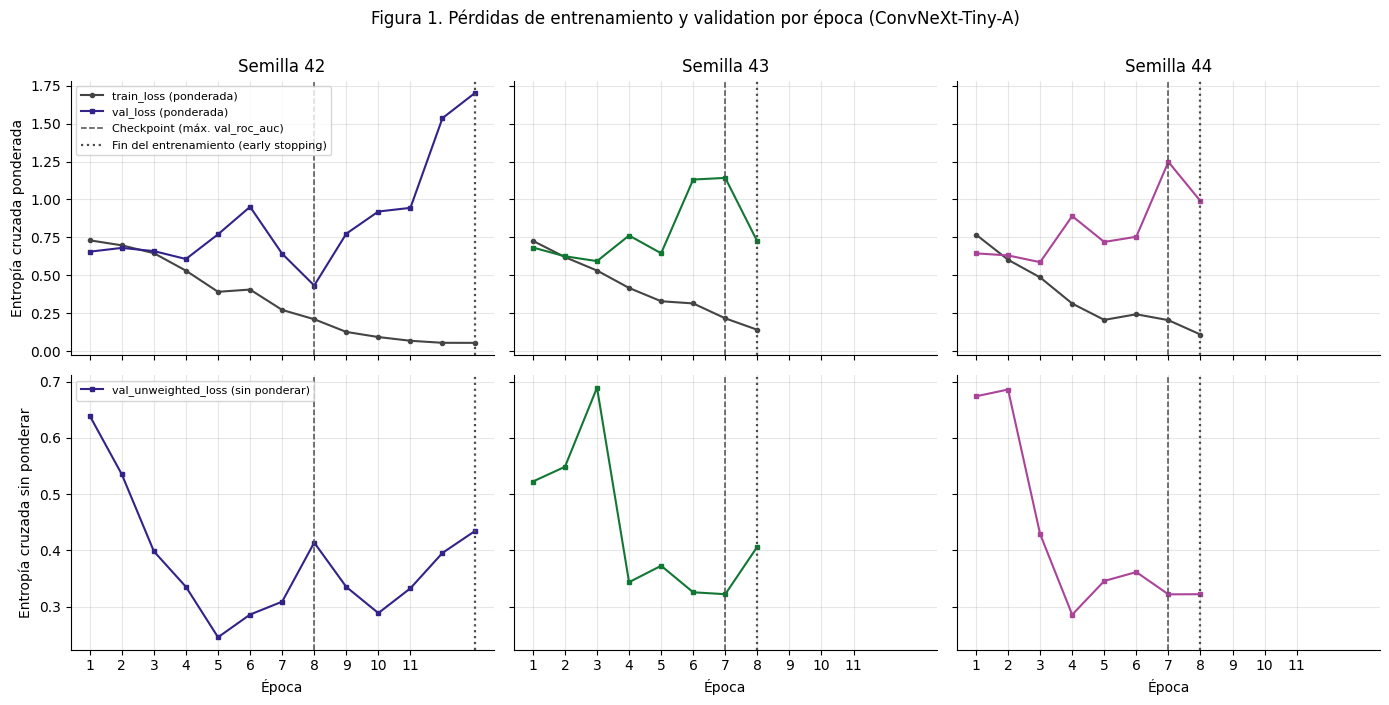

In [11]:
MAX_EPOCH = max(len(h) for h in histories.values())


def mark_epochs(ax, seed, with_legend=False):
    config = run_configs[seed]
    ax.axvline(
        config["epoch_best"], color="0.3", ls="--", lw=1.1,
        label="Checkpoint (máx. val_roc_auc)" if with_legend else "_nolegend_",
    )
    ax.axvline(
        config["early_stopped_at_epoch"], color="0.3", ls=":", lw=1.6,
        label="Fin del entrenamiento (early stopping)" if with_legend else "_nolegend_",
    )


fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey="row")
for col, seed in enumerate(SEEDS):
    h = HISTORY[seed]

    ax = axes[0, col]
    ax.plot(h.index, h["train_loss"], marker="o", ms=3, color="#444444", label="train_loss (ponderada)")
    ax.plot(h.index, h["val_loss"], marker="s", ms=3, color=SEED_COLORS[seed], label="val_loss (ponderada)")
    mark_epochs(ax, seed, with_legend=(col == 0))
    ax.set_title(f"Semilla {seed}")

    ax = axes[1, col]
    ax.plot(h.index, h["val_unweighted_loss"], marker="s", ms=3, color=SEED_COLORS[seed], label="val_unweighted_loss (sin ponderar)")
    mark_epochs(ax, seed, with_legend=False)
    ax.set_xlabel("Época")
    ax.set_xticks(range(1, MAX_EPOCH + 1))

axes[0, 0].set_ylabel("Entropía cruzada ponderada")
axes[1, 0].set_ylabel("Entropía cruzada sin ponderar")
for row in range(2):
    axes[row, 0].legend(fontsize=8, loc="best")
fig.suptitle("Figura 1. Pérdidas de entrenamiento y validation por época (ConvNeXt-Tiny-A)", y=1.0)
fig.tight_layout()
save_figure(fig, "f1_curvas_perdida")
plt.show()

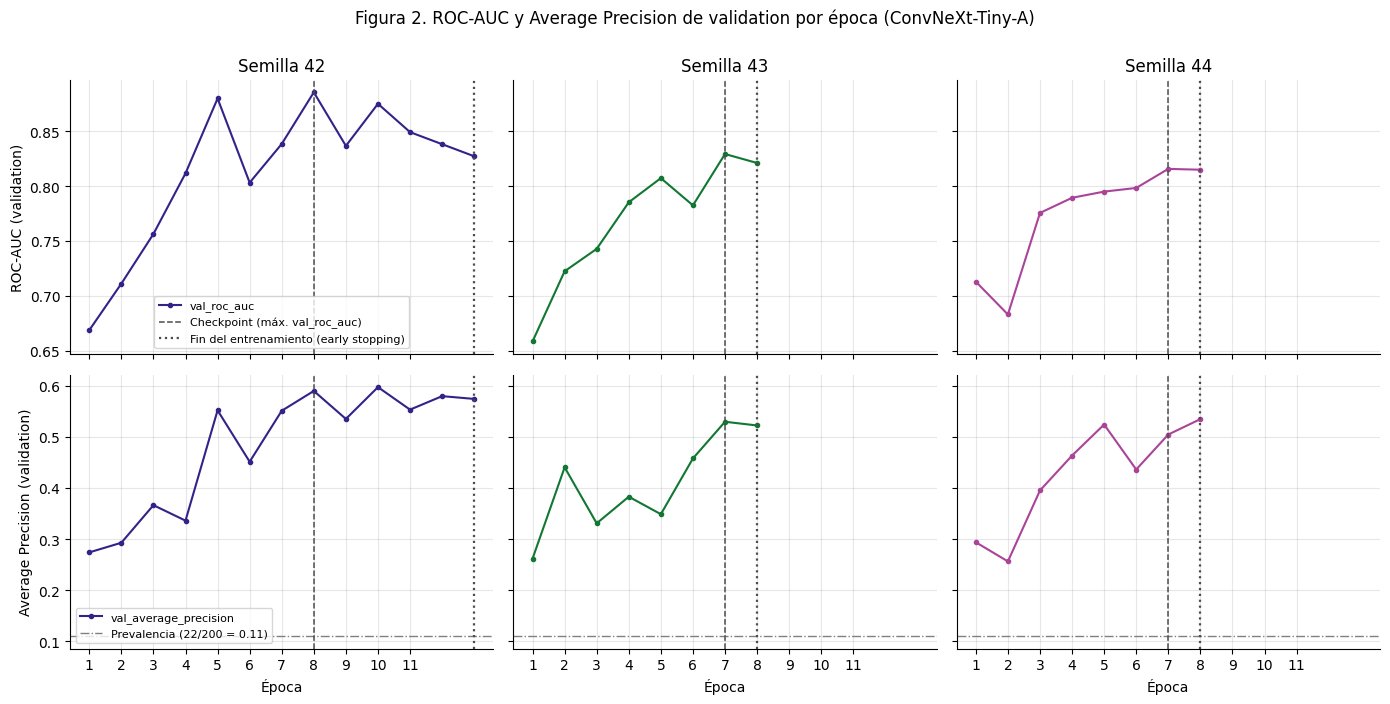

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey="row")
for col, seed in enumerate(SEEDS):
    h = HISTORY[seed]

    ax = axes[0, col]
    ax.plot(h.index, h["val_roc_auc"], marker="o", ms=3, color=SEED_COLORS[seed], label="val_roc_auc")
    mark_epochs(ax, seed, with_legend=(col == 0))
    ax.set_title(f"Semilla {seed}")

    ax = axes[1, col]
    ax.plot(h.index, h["val_average_precision"], marker="o", ms=3, color=SEED_COLORS[seed], label="val_average_precision")
    ax.axhline(PREVALENCE, color="0.5", ls="-.", lw=1, label=f"Prevalencia ({N_MALIGNANT}/{N_VALIDATION} = {PREVALENCE:.2f})" if col == 0 else "_nolegend_")
    mark_epochs(ax, seed, with_legend=False)
    ax.set_xlabel("Época")
    ax.set_xticks(range(1, MAX_EPOCH + 1))

axes[0, 0].set_ylabel("ROC-AUC (validation)")
axes[1, 0].set_ylabel("Average Precision (validation)")
for row in range(2):
    axes[row, 0].legend(fontsize=8, loc="best")
fig.suptitle("Figura 2. ROC-AUC y Average Precision de validation por época (ConvNeXt-Tiny-A)", y=1.0)
fig.tight_layout()
save_figure(fig, "f2_curvas_auc_ap")
plt.show()

**Descriptores numéricos de la trayectoria**

In [13]:
def describe_trajectory(seed):
    h = HISTORY[seed]
    config = run_configs[seed]
    epoch_best = config["epoch_best"]
    epoch_last = int(h.index.max())
    epoch_min_loss = int(h["val_loss"].idxmin())
    epoch_min_unweighted = int(h["val_unweighted_loss"].idxmin())
    epoch_max_ap = int(h["val_average_precision"].idxmax())

    return {
        "seed": seed,
        "epocas_ejecutadas": epoch_last,
        "epoca_min_val_loss": epoch_min_loss,
        "val_loss_min": h.loc[epoch_min_loss, "val_loss"],
        "val_loss_checkpoint": h.loc[epoch_best, "val_loss"],
        "val_loss_final": h.loc[epoch_last, "val_loss"],
        "train_loss_en_min_val_loss": h.loc[epoch_min_loss, "train_loss"],
        "train_loss_checkpoint": h.loc[epoch_best, "train_loss"],
        "train_loss_final": h.loc[epoch_last, "train_loss"],
        "brecha_val_menos_train_checkpoint": h.loc[epoch_best, "val_loss"] - h.loc[epoch_best, "train_loss"],
        "brecha_val_menos_train_final": h.loc[epoch_last, "val_loss"] - h.loc[epoch_last, "train_loss"],
        "n_epocas_con_aumento_val_loss": int((h["val_loss"].diff().dropna() > 0).sum()),
        "epoca_min_val_unweighted": epoch_min_unweighted,
        "val_unweighted_min": h.loc[epoch_min_unweighted, "val_unweighted_loss"],
        "val_unweighted_checkpoint": h.loc[epoch_best, "val_unweighted_loss"],
        "val_unweighted_final": h.loc[epoch_last, "val_unweighted_loss"],
        "val_roc_auc_checkpoint": h.loc[epoch_best, "val_roc_auc"],
        "val_roc_auc_final": h.loc[epoch_last, "val_roc_auc"],
        "rango_val_roc_auc": h["val_roc_auc"].max() - h["val_roc_auc"].min(),
        "cambio_abs_medio_roc_auc": h["val_roc_auc"].diff().abs().mean(),
        "epoca_max_val_ap": epoch_max_ap,
        "val_ap_max": h.loc[epoch_max_ap, "val_average_precision"],
        "val_ap_checkpoint": h.loc[epoch_best, "val_average_precision"],
        "val_ap_final": h.loc[epoch_last, "val_average_precision"],
        "rango_val_ap": h["val_average_precision"].max() - h["val_average_precision"].min(),
        "cambio_abs_medio_ap": h["val_average_precision"].diff().abs().mean(),
    }


evolution = pd.DataFrame([describe_trajectory(seed) for seed in SEEDS])
save_table(evolution, "t3_evolucion_descriptiva")
evolution.round(4).set_index("seed").T

seed,42,43,44
epocas_ejecutadas,13.0000,8.0000,8.0000
epoca_min_val_loss,8.0000,3.0000,3.0000
val_loss_min,0.4321,0.5930,0.5860
val_loss_checkpoint,0.4321,1.1421,1.2478
val_loss_final,1.7001,0.7230,0.9891
train_loss_en_min_val_loss,0.2096,0.5308,0.4856
train_loss_checkpoint,0.2096,0.2156,0.2035
train_loss_final,0.0537,0.1401,0.1087
brecha_val_menos_train_checkpoint,0.2226,0.9265,1.0443
brecha_val_menos_train_final,1.6464,0.5829,0.8804


## 4. Early stopping y selección del checkpoint

En R4, el **entrenamiento se detiene** con `val_weighted_loss` (paciencia 5, `min_delta` 0.001), mientras que el **checkpoint** se elige por el máximo `val_roc_auc` (primera época en caso de empate).

Este apartado:
1. reconstruye el contador de paciencia a partir de `val_loss`, aplicando la misma regla y comprueba que reproduce la época de parada registrada
2. compara la época del mínimo de `val_loss` con la época del checkpoint por ROC-AUC.

In [14]:
PATIENCE = run_configs[SEEDS[0]]["patience"]
MIN_DELTA = run_configs[SEEDS[0]]["min_delta"]


def reconstruct_early_stopping(val_losses, patience, min_delta):
    # Misma regla que train.py: la referencia solo se actualiza si la mejora supera min_delta
    reference = float("inf")
    counter = 0
    rows = []
    stop_epoch = None

    for epoch, loss in enumerate(val_losses, start=1):
        previous_reference = reference
        improved = loss < (reference - min_delta)
        if improved:
            reference = loss
            counter = 0
        else:
            counter += 1
        stops = counter >= patience
        rows.append(
            {
                "epoch": epoch,
                "val_loss": loss,
                "referencia_previa": np.nan if np.isinf(previous_reference) else previous_reference,
                "mejora_mayor_a_min_delta": improved,
                "contador_paciencia": counter,
                "detiene": stops,
            }
        )
        if stops:
            stop_epoch = epoch
            break

    return pd.DataFrame(rows), stop_epoch


traces = {}
for seed in SEEDS:
    trace, stop_epoch = reconstruct_early_stopping(histories[seed]["val_loss"], PATIENCE, MIN_DELTA)
    assert stop_epoch == run_configs[seed]["early_stopped_at_epoch"], (seed, stop_epoch)
    assert len(trace) == run_configs[seed]["epochs_run"], seed
    traces[seed] = trace

print(f"Contador de paciencia reconstruido (paciencia={PATIENCE}, min_delta={MIN_DELTA}): reproduce la época de parada de las 3 semillas.")

stopping_summary = pd.DataFrame(
    [
        {
            "seed": seed,
            "epoca_ultima_mejora_early_stopping": int(traces[seed].loc[traces[seed]["mejora_mayor_a_min_delta"], "epoch"].max()),
            "epoca_min_val_loss": int(HISTORY[seed]["val_loss"].idxmin()),
            "epoca_checkpoint_max_roc_auc": run_configs[seed]["epoch_best"],
            "epoca_fin_entrenamiento": run_configs[seed]["early_stopped_at_epoch"],
            "criterios_coinciden_en_la_misma_epoca": int(HISTORY[seed]["val_loss"].idxmin()) == run_configs[seed]["epoch_best"],
        }
        for seed in SEEDS
    ]
)

save_table(stopping_summary, "t2b_resumen_criterios")
save_table(pd.concat([t.assign(seed=s) for s, t in traces.items()], ignore_index=True), "t2c_traza_early_stopping")
stopping_summary

Contador de paciencia reconstruido (paciencia=5, min_delta=0.001): reproduce la época de parada de las 3 semillas.


,seed,epoca_ultima_mejora_early_stopping,epoca_min_val_loss,epoca_checkpoint_max_roc_auc,epoca_fin_entrenamiento,criterios_coinciden_en_la_misma_epoca
0,42,8,8,8,13,True
1,43,3,3,7,8,False
2,44,3,3,7,8,False


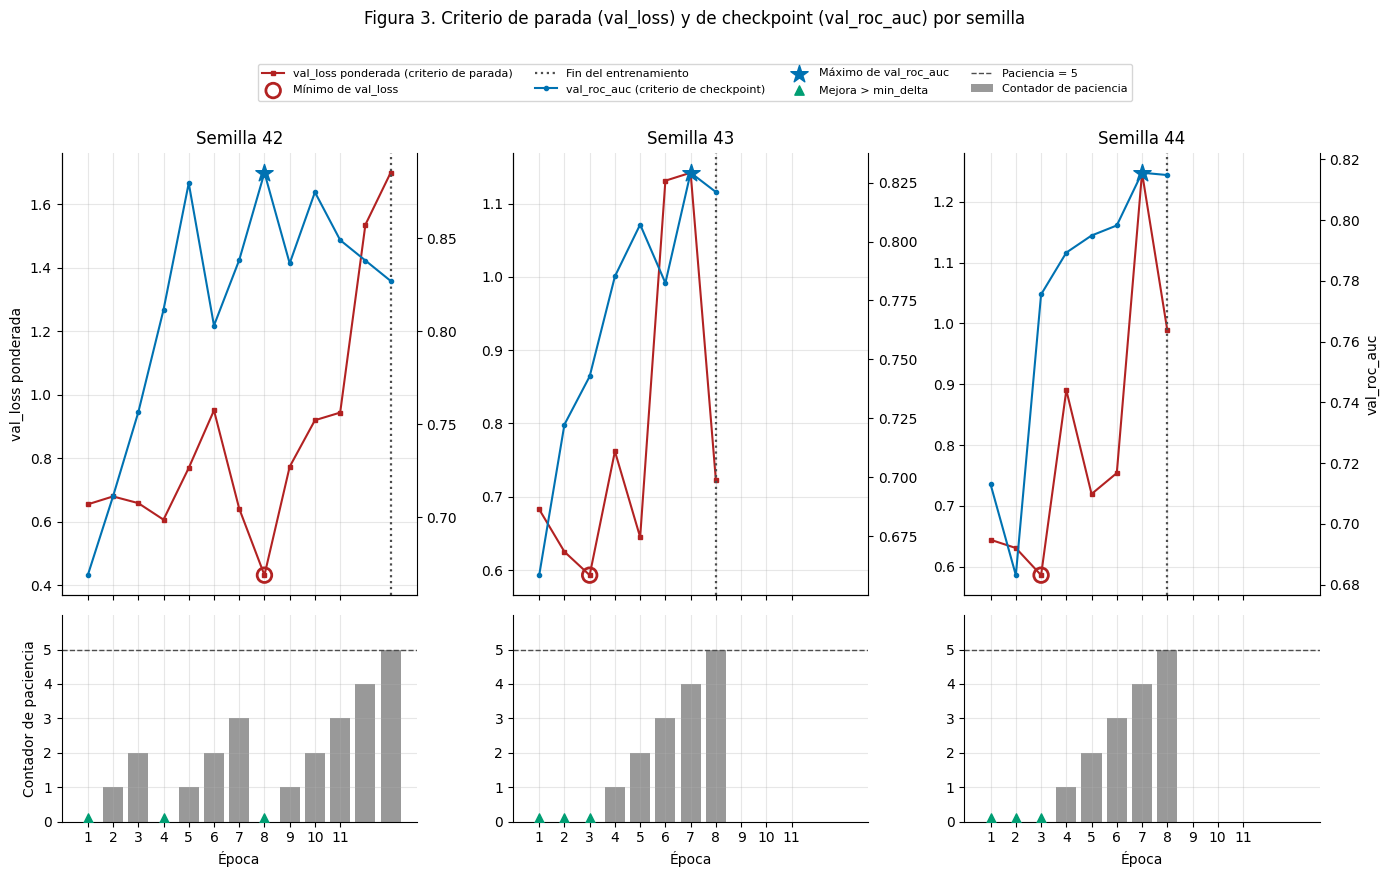

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1.4]})
twin_axes = {}

for col, seed in enumerate(SEEDS):
    h = HISTORY[seed]
    trace = traces[seed]
    config = run_configs[seed]
    epoch_min_loss = int(h["val_loss"].idxmin())

    ax = axes[0, col]
    ax.plot(h.index, h["val_loss"], marker="s", ms=3, color="#B22222", label="val_loss ponderada (criterio de parada)")
    ax.scatter([epoch_min_loss], [h.loc[epoch_min_loss, "val_loss"]], s=110, facecolors="none", edgecolors="#B22222", linewidths=2, zorder=5, label="Mínimo de val_loss")
    ax.set_title(f"Semilla {seed}")

    ax_auc = ax.twinx()
    ax_auc.spines["right"].set_visible(True)
    ax_auc.grid(False)
    ax_auc.plot(h.index, h["val_roc_auc"], marker="o", ms=3, color="#0072B2", label="val_roc_auc (criterio de checkpoint)")
    ax_auc.scatter([config["epoch_best"]], [h.loc[config["epoch_best"], "val_roc_auc"]], marker="*", s=170, color="#0072B2", zorder=5, label="Máximo de val_roc_auc")
    ax.axvline(config["early_stopped_at_epoch"], color="0.3", ls=":", lw=1.6, label="Fin del entrenamiento")
    twin_axes[seed] = ax_auc
    if col == 0:
        ax.set_ylabel("val_loss ponderada")
    if col == len(SEEDS) - 1:
        ax_auc.set_ylabel("val_roc_auc")

    ab = axes[1, col]
    improved = trace["mejora_mayor_a_min_delta"].to_numpy()
    ab.bar(trace["epoch"], trace["contador_paciencia"], color="#999999", label="Contador de paciencia")
    ab.scatter(trace.loc[improved, "epoch"], np.full(int(improved.sum()), 0.12), marker="^", s=45, color="#009E73", zorder=5, label="Mejora > min_delta")
    ab.axhline(PATIENCE, color="0.3", ls="--", lw=1, label=f"Paciencia = {PATIENCE}")
    ab.set_ylim(0, PATIENCE + 1)
    ab.set_yticks(range(PATIENCE + 1))
    ab.set_xlabel("Época")
    ab.set_xticks(range(1, MAX_EPOCH + 1))
    if col == 0:
        ab.set_ylabel("Contador de paciencia")

legend_handles, legend_labels = [], []
for source in [axes[0, 0], twin_axes[SEEDS[0]], axes[1, 0]]:
    h_, l_ = source.get_legend_handles_labels()
    legend_handles += h_
    legend_labels += l_
fig.legend(legend_handles, legend_labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.03), fontsize=8)
fig.suptitle("Figura 3. Criterio de parada (val_loss) y de checkpoint (val_roc_auc) por semilla", y=1.09)
fig.tight_layout()
save_figure(fig, "f3_criterios_parada_checkpoint")
plt.show()

Se muestra las métricas del historial (umbral 0.5) en tres épocas de referencia por semilla: el mínimo de `val_loss` (criterio de parada), el checkpoint de R4 (máximo `val_roc_auc`) y el máximo de `val_average_precision` (métrica con la que R6 seleccionó la configuración). 

Adicionalmente, se presenta la diferencia (mínimo de `val_loss` − checkpoint de R4) en cada métrica, por semilla.

In [16]:
COMPARISON_METRICS = [
    "val_loss", "val_unweighted_loss", "val_roc_auc", "val_average_precision",
    "val_recall_malignant", "val_specificity", "val_balanced_accuracy",
]


def reference_epochs(seed):
    h = HISTORY[seed]
    return {
        "Mínimo de val_loss (criterio de parada)": int(h["val_loss"].idxmin()),
        "Checkpoint R4 (máx. val_roc_auc)": run_configs[seed]["epoch_best"],
        "Solo referencia: máx. val_average_precision": int(h["val_average_precision"].idxmax()),
    }


comparison_rows = []
for seed in SEEDS:
    for label, epoch in reference_epochs(seed).items():
        comparison_rows.append(
            {
                "seed": seed,
                "criterio": label,
                "epoca": epoch,
                **{metric: HISTORY[seed].loc[epoch, metric] for metric in COMPARISON_METRICS},
            }
        )
criteria_comparison = pd.DataFrame(comparison_rows)

difference_rows = []
for seed in SEEDS:
    epoch_min_loss = int(HISTORY[seed]["val_loss"].idxmin())
    epoch_checkpoint = run_configs[seed]["epoch_best"]
    difference_rows.append(
        {
            "seed": seed,
            "epoca_min_val_loss": epoch_min_loss,
            "epoca_checkpoint": epoch_checkpoint,
            "diferencia_de_epocas": epoch_min_loss - epoch_checkpoint,
            **{
                f"delta_{metric}": HISTORY[seed].loc[epoch_min_loss, metric] - HISTORY[seed].loc[epoch_checkpoint, metric]
                for metric in COMPARISON_METRICS
            },
        }
    )
criteria_differences = pd.DataFrame(difference_rows)

save_table(criteria_comparison, "t4_comparacion_criterios")
save_table(criteria_differences, "t4b_diferencias_min_loss_vs_checkpoint")
display(criteria_comparison.round(4))
display(criteria_differences.round(4))

,seed,criterio,epoca,val_loss,val_unweighted_loss,val_roc_auc,val_average_precision,val_recall_malignant,val_specificity,val_balanced_accuracy
0,42,Mínimo de val_loss (criterio de parada),8,0.4321,0.4137,0.8853,0.5898,0.7727,0.7753,0.7740
1,42,Checkpoint R4 (máx. val_roc_auc),8,0.4321,0.4137,0.8853,0.5898,0.7727,0.7753,0.7740
2,42,Solo referencia: máx. val_average_precision,10,0.9203,0.2884,0.8749,0.5972,0.4545,0.9551,0.7048
3,43,Mínimo de val_loss (criterio de parada),3,0.5930,0.6891,0.7428,0.3309,0.8182,0.5506,0.6844
4,43,Checkpoint R4 (máx. val_roc_auc),7,1.1421,0.3220,0.8292,0.5295,0.3182,0.9775,0.6479
5,43,Solo referencia: máx. val_average_precision,7,1.1421,0.3220,0.8292,0.5295,0.3182,0.9775,0.6479
6,44,Mínimo de val_loss (criterio de parada),3,0.5860,0.4289,0.7755,0.3952,0.5909,0.8315,0.7112
7,44,Checkpoint R4 (máx. val_roc_auc),7,1.2478,0.3217,0.8156,0.5046,0.2727,0.9944,0.6336
8,44,Solo referencia: máx. val_average_precision,8,0.9891,0.3219,0.8149,0.5347,0.4091,0.9607,0.6849


,seed,epoca_min_val_loss,epoca_checkpoint,diferencia_de_epocas,delta_val_loss,delta_val_unweighted_loss,delta_val_roc_auc,delta_val_average_precision,delta_val_recall_malignant,delta_val_specificity,delta_val_balanced_accuracy
0,42,8,8,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,43,3,7,-4,-0.5490,0.3671,-0.0863,-0.1987,0.5000,-0.4270,0.0365
2,44,3,7,-4,-0.6618,0.1072,-0.0401,-0.1094,0.3182,-0.1629,0.0776


## 5. Distribución de probabilidades

Se utilizan exclusivamente las predicciones de `validation` del checkpoint de cada semilla. El umbral 0.5 se dibuja solo como referencia visual, sin optimizarlo.

In [17]:
pred = pd.concat([predictions[seed].assign(seed=seed) for seed in SEEDS], ignore_index=True)
pred["y_pred"] = (pred["probability_malignant"] >= THRESHOLD).astype(int)
pred["outcome"] = np.select(
    [
        (pred["y_true"] == 0) & (pred["y_pred"] == 0),
        (pred["y_true"] == 0) & (pred["y_pred"] == 1),
        (pred["y_true"] == 1) & (pred["y_pred"] == 0),
        (pred["y_true"] == 1) & (pred["y_pred"] == 1),
    ],
    ["TN", "FP", "FN", "TP"],
    default="",
)
assert (pred["outcome"] != "").all()

prob_wide = pred.pivot(index="image_id", columns="seed", values="probability_malignant")
labels = predictions[SEEDS[0]].set_index("image_id")["y_true"]
assert prob_wide.index.isin(labels.index).all() and len(prob_wide) == N_VALIDATION

prob_stats = (
    pred.groupby(["seed", "y_true"])["probability_malignant"]
    .agg(
        n="count",
        media="mean",
        desviacion="std",
        minimo="min",
        p25=lambda s: s.quantile(0.25),
        mediana="median",
        p75=lambda s: s.quantile(0.75),
        maximo="max",
        proporcion_mayor_igual_umbral=lambda s: (s >= THRESHOLD).mean(),
    )
    .reset_index()
)
prob_stats.insert(2, "clase", prob_stats["y_true"].map(CLASS_NAMES))

save_table(prob_stats, "t5_probabilidades_por_clase")
prob_stats.round(4)

,seed,y_true,clase,n,media,desviacion,minimo,p25,mediana,p75,maximo,proporcion_mayor_igual_umbral
0,42,0,Benigna (0),178,0.2264,0.2915,0.0005,0.0129,0.0702,0.3692,0.9594,0.2247
1,42,1,Maligna (1),22,0.7200,0.2952,0.0627,0.6356,0.8120,0.9816,0.9981,0.7727
2,43,0,Benigna (0),178,0.0418,0.1315,0.0002,0.0013,0.0055,0.0162,0.9311,0.0225
3,43,1,Maligna (1),22,0.3569,0.4062,0.0020,0.0173,0.1159,0.8444,0.9820,0.3182
4,44,0,Benigna (0),178,0.0311,0.0820,0.0002,0.0015,0.0035,0.0202,0.7645,0.0056
5,44,1,Maligna (1),22,0.2906,0.3797,0.0007,0.0167,0.0758,0.6228,0.9649,0.2727


Se presenta la separación entre clases por semilla: diferencia de medianas (maligna − benigna) y **coeficiente de solapamiento** de los histogramas de ambas clases, Se acompaña del ROC-AUC y la prevalencia.

Adicionalmente, el acuerdo entre semillas a nivel de imagen: correlación de Spearman y de Pearson de `probability_malignant` entre pares de semillas, y diferencia absoluta media, globalmente y por clase real.

In [18]:
BINS = np.linspace(0, 1, 21)


def overlap_coefficient(prob_benign, prob_malignant, bins=BINS):
    hist_benign, _ = np.histogram(prob_benign, bins=bins)
    hist_malignant, _ = np.histogram(prob_malignant, bins=bins)
    return float(np.minimum(hist_benign / hist_benign.sum(), hist_malignant / hist_malignant.sum()).sum())


separation_rows = []
for seed in SEEDS:
    df = predictions[seed]
    benign = df.loc[df["y_true"] == 0, "probability_malignant"].to_numpy()
    malignant = df.loc[df["y_true"] == 1, "probability_malignant"].to_numpy()
    separation_rows.append(
        {
            "seed": seed,
            "mediana_benigna": float(np.median(benign)),
            "mediana_maligna": float(np.median(malignant)),
            "diferencia_de_medianas": float(np.median(malignant) - np.median(benign)),
            "coeficiente_solapamiento": overlap_coefficient(benign, malignant),
            "roc_auc": float(roc_auc_score(df["y_true"], df["probability_malignant"])),
        }
    )
separation = pd.DataFrame(separation_rows)

pairs = list(itertools.combinations(SEEDS, 2))
groups = {
    "Todas": labels.index,
    "Benignas": labels.index[labels == 0],
    "Malignas": labels.index[labels == 1],
}
agreement_rows = []
for a, b in pairs:
    for group_name, index in groups.items():
        x, y = prob_wide.loc[index, a], prob_wide.loc[index, b]
        agreement_rows.append(
            {
                "par_de_semillas": f"{a} vs {b}",
                "grupo": group_name,
                "n": len(index),
                "spearman": x.corr(y, method="spearman"),
                "pearson": x.corr(y),
                "diferencia_abs_media": float((x - y).abs().mean()),
            }
        )
agreement = pd.DataFrame(agreement_rows)

save_table(separation, "t5b_separacion_entre_clases")
save_table(agreement, "t5c_acuerdo_entre_semillas")
display(separation.round(4))
display(agreement.round(4))

,seed,mediana_benigna,mediana_maligna,diferencia_de_medianas,coeficiente_solapamiento,roc_auc
0,42,0.0702,0.8120,0.7418,0.2589,0.8853
1,43,0.0055,0.1159,0.1104,0.4198,0.8292
2,44,0.0035,0.0758,0.0723,0.5444,0.8156


,par_de_semillas,grupo,n,spearman,pearson,diferencia_abs_media
0,42 vs 43,Todas,200,0.5905,0.5963,0.2087
1,42 vs 43,Benignas,178,0.5128,0.5340,0.1869
2,42 vs 43,Malignas,22,0.6736,0.5577,0.3848
3,42 vs 44,Todas,200,0.5346,0.4441,0.2352
4,42 vs 44,Benignas,178,0.4643,0.3592,0.2048
5,42 vs 44,Malignas,22,0.5471,0.3542,0.4812
6,43 vs 44,Todas,200,0.7024,0.7872,0.0487
7,43 vs 44,Benignas,178,0.6546,0.6075,0.0385
8,43 vs 44,Malignas,22,0.8001,0.8120,0.1314


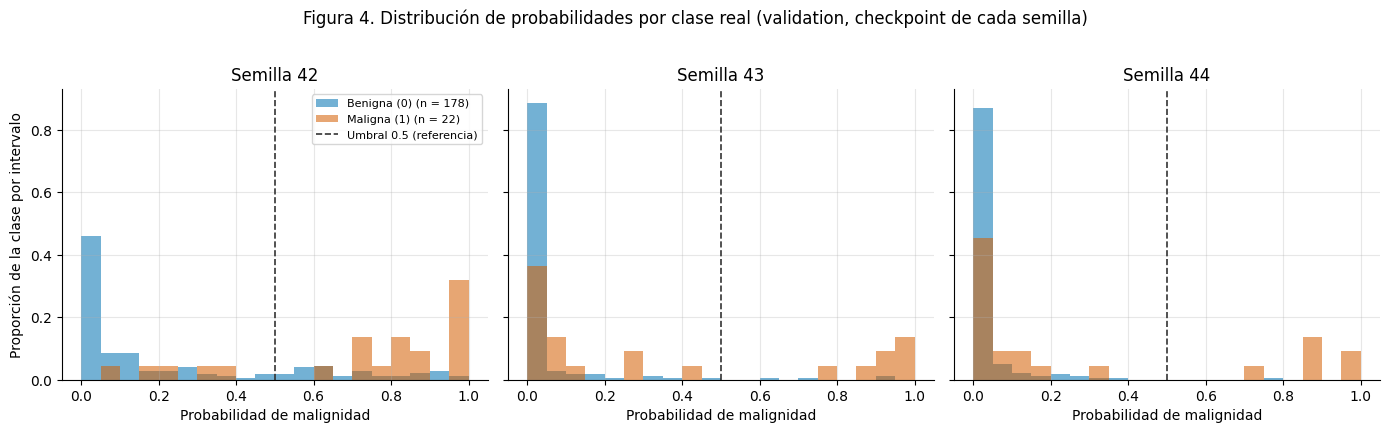

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
for ax, seed in zip(axes, SEEDS):
    df = predictions[seed]
    for cls in (0, 1):
        values = df.loc[df["y_true"] == cls, "probability_malignant"].to_numpy()
        ax.hist(
            values, bins=BINS, weights=np.full(len(values), 1 / len(values)),
            color=CLASS_COLORS[cls], alpha=0.55, label=f"{CLASS_NAMES[cls]} (n = {len(values)})",
        )
    ax.axvline(THRESHOLD, color="0.2", ls="--", lw=1.2, label="Umbral 0.5 (referencia)")
    ax.set_title(f"Semilla {seed}")
    ax.set_xlabel("Probabilidad de malignidad")
axes[0].set_ylabel("Proporción de la clase por intervalo")
axes[0].legend(fontsize=8)
fig.suptitle("Figura 4. Distribución de probabilidades por clase real (validation, checkpoint de cada semilla)", y=1.02)
fig.tight_layout()
save_figure(fig, "f4_histogramas_probabilidad")
plt.show()

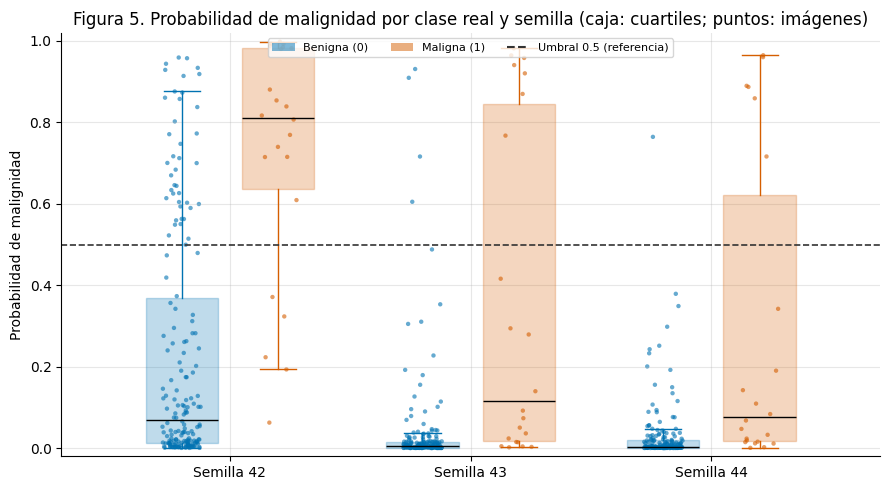

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))
rng = np.random.default_rng(2026)  # solo para el desplazamiento horizontal de los puntos (jitter)

for i, seed in enumerate(SEEDS):
    df = predictions[seed]
    for cls in (0, 1):
        values = df.loc[df["y_true"] == cls, "probability_malignant"].to_numpy()
        position = i + (-0.2 if cls == 0 else 0.2)
        ax.boxplot(
            values, positions=[position], widths=0.3, showfliers=False, patch_artist=True,
            boxprops=dict(facecolor=CLASS_COLORS[cls], alpha=0.25, edgecolor=CLASS_COLORS[cls]),
            medianprops=dict(color="black"),
            whiskerprops=dict(color=CLASS_COLORS[cls]),
            capprops=dict(color=CLASS_COLORS[cls]),
        )
        ax.scatter(
            position + rng.uniform(-0.08, 0.08, len(values)), values,
            s=10, alpha=0.6, color=CLASS_COLORS[cls], edgecolors="none",
        )

ax.axhline(THRESHOLD, color="0.2", ls="--", lw=1.2)
ax.set_xticks(range(len(SEEDS)))
ax.set_xticklabels([f"Semilla {seed}" for seed in SEEDS])
ax.set_ylabel("Probabilidad de malignidad")
ax.set_ylim(-0.02, 1.02)
ax.legend(
    handles=[
        Patch(facecolor=CLASS_COLORS[0], alpha=0.5, label=CLASS_NAMES[0]),
        Patch(facecolor=CLASS_COLORS[1], alpha=0.5, label=CLASS_NAMES[1]),
        Line2D([0], [0], color="0.2", ls="--", label="Umbral 0.5 (referencia)"),
    ],
    fontsize=8, loc="upper center", ncol=3,
)
ax.set_title("Figura 5. Probabilidad de malignidad por clase real y semilla (caja: cuartiles; puntos: imágenes)")
fig.tight_layout()
save_figure(fig, "f5_cajas_probabilidad")
plt.show()

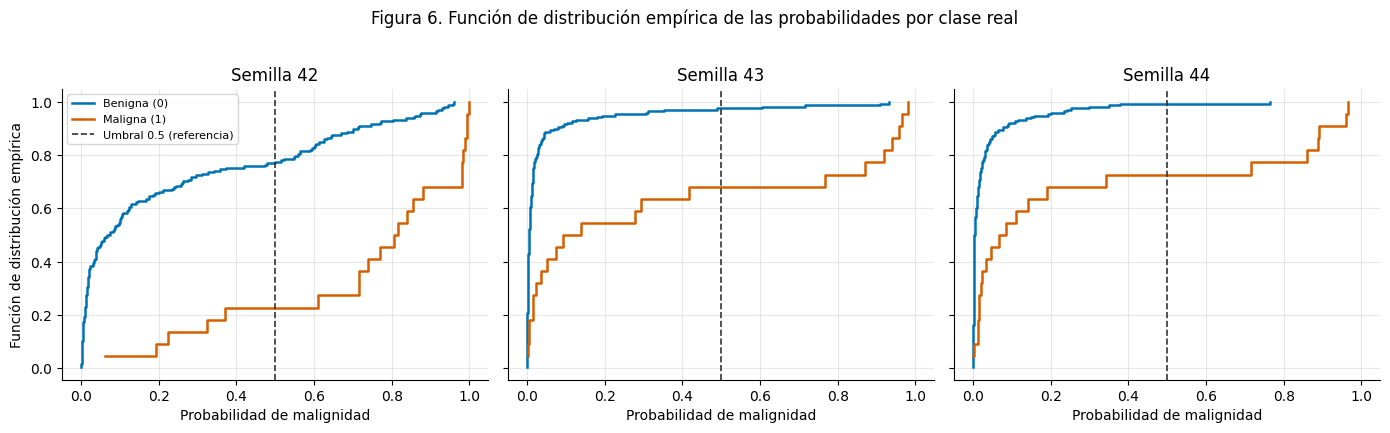

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
for ax, seed in zip(axes, SEEDS):
    df = predictions[seed]
    for cls in (0, 1):
        values = np.sort(df.loc[df["y_true"] == cls, "probability_malignant"].to_numpy())
        ecdf = np.arange(1, len(values) + 1) / len(values)
        ax.step(values, ecdf, where="post", color=CLASS_COLORS[cls], lw=1.8, label=CLASS_NAMES[cls])
    ax.axvline(THRESHOLD, color="0.2", ls="--", lw=1.2, label="Umbral 0.5 (referencia)")
    ax.set_title(f"Semilla {seed}")
    ax.set_xlabel("Probabilidad de malignidad")
axes[0].set_ylabel("Función de distribución empírica")
axes[0].legend(fontsize=8)
fig.suptitle("Figura 6. Función de distribución empírica de las probabilidades por clase real", y=1.02)
fig.tight_layout()
save_figure(fig, "f6_ecdf_probabilidad")
plt.show()

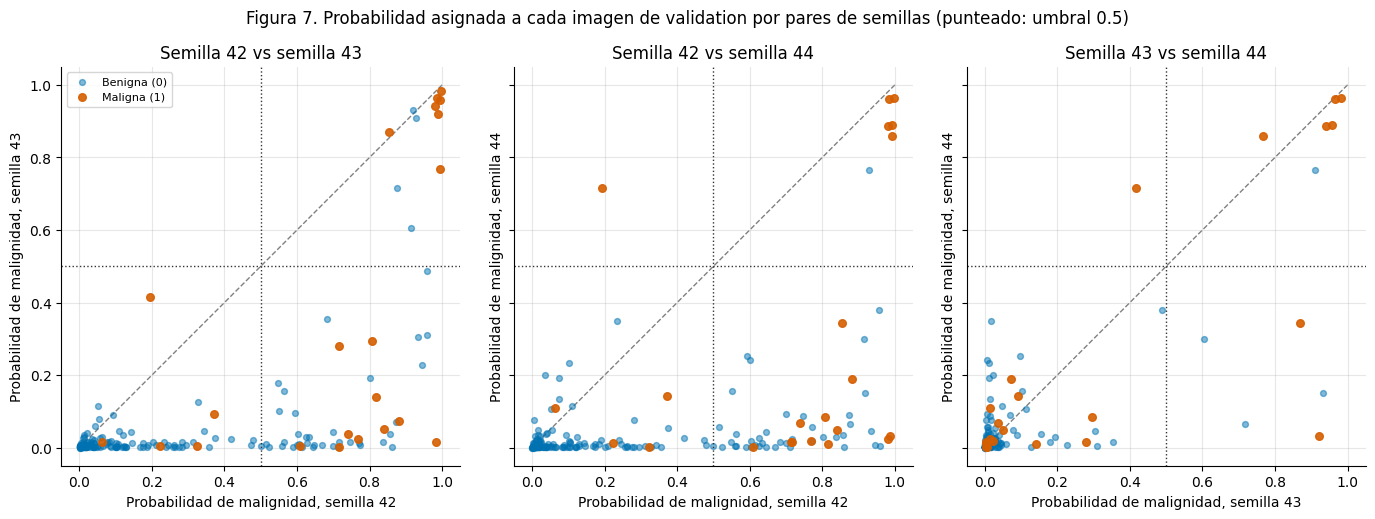

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharex=True, sharey=True)
for ax, (a, b) in zip(axes, pairs):
    for cls in (0, 1):
        index = labels.index[labels == cls]
        ax.scatter(
            prob_wide.loc[index, a], prob_wide.loc[index, b],
            s=18 if cls == 0 else 30, alpha=0.5 if cls == 0 else 0.9,
            color=CLASS_COLORS[cls], label=CLASS_NAMES[cls], zorder=2 + cls,
        )
    ax.plot([0, 1], [0, 1], color="0.5", lw=1, ls="--", zorder=1)
    ax.axvline(THRESHOLD, color="0.2", ls=":", lw=1)
    ax.axhline(THRESHOLD, color="0.2", ls=":", lw=1)
    ax.set_xlabel(f"Probabilidad de malignidad, semilla {a}")
    ax.set_ylabel(f"Probabilidad de malignidad, semilla {b}")
    ax.set_title(f"Semilla {a} vs semilla {b}")
    ax.set_aspect("equal")
axes[0].legend(fontsize=8)
fig.suptitle("Figura 7. Probabilidad asignada a cada imagen de validation por pares de semillas (punteado: umbral 0.5)", y=1.02)
fig.tight_layout()
save_figure(fig, "f7_dispersion_entre_semillas")
plt.show()

## 6. Curvas Precision-Recall por semilla

Curvas Precision-Recall calculadas con las predicciones existentes de `validation`. La línea punteada es la prevalencia de la clase maligna (precisión de un clasificador sin información). 
El círculo relleno marca el punto de operación del umbral fijo 0.5; no se explora ni se propone otro umbral.

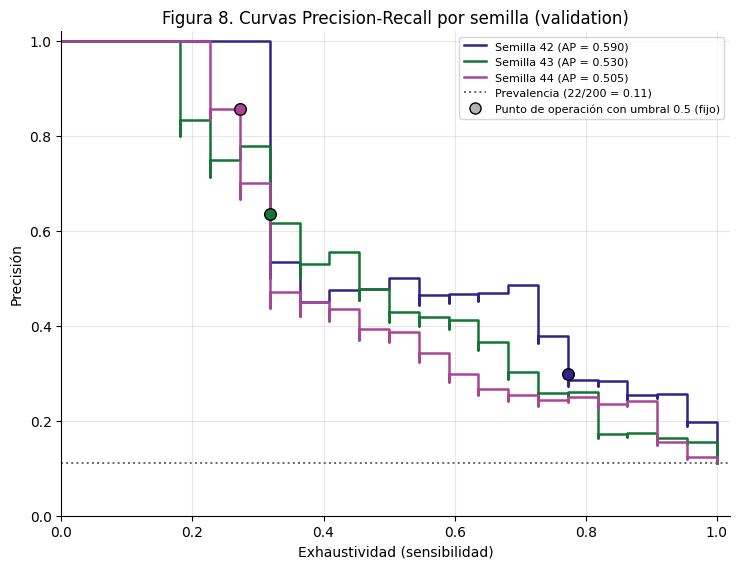

,seed,prevalencia,average_precision,ap_sobre_prevalencia,precision_a_umbral_0.5,recall_a_umbral_0.5,precision_max_con_recall_>=_0.5,precision_max_con_recall_>=_0.7,precision_max_con_recall_>=_0.9
0,42,0.11,0.5898,5.3616,0.2982,0.7727,0.5000,0.4848,0.2561
1,43,0.11,0.5295,4.8138,0.6364,0.3182,0.4783,0.3019,0.1739
2,44,0.11,0.5046,4.5871,0.8571,0.2727,0.3929,0.2540,0.2410


In [23]:
metrics_by_seed = baseline_metrics.set_index("seed")

fig, ax = plt.subplots(figsize=(7.5, 5.8))
pr_rows = []
for seed in SEEDS:
    df = predictions[seed]
    precision, recall, _ = precision_recall_curve(df["y_true"], df["probability_malignant"])
    average_precision = float(average_precision_score(df["y_true"], df["probability_malignant"]))

    ax.step(recall, precision, where="post", color=SEED_COLORS[seed], lw=1.8, label=f"Semilla {seed} (AP = {average_precision:.3f})")
    ax.scatter(
        [metrics_by_seed.loc[seed, "sensitivity"]], [metrics_by_seed.loc[seed, "precision"]],
        s=70, color=SEED_COLORS[seed], edgecolors="black", zorder=5,
    )

    row = {
        "seed": seed,
        "prevalencia": PREVALENCE,
        "average_precision": average_precision,
        "ap_sobre_prevalencia": average_precision / PREVALENCE,
        "precision_a_umbral_0.5": metrics_by_seed.loc[seed, "precision"],
        "recall_a_umbral_0.5": metrics_by_seed.loc[seed, "sensitivity"],
    }
    for target in (0.5, 0.7, 0.9):
        row[f"precision_max_con_recall_>=_{target}"] = float(precision[recall >= target].max())
    pr_rows.append(row)

ax.axhline(PREVALENCE, color="0.4", ls=":", lw=1.4, label=f"Prevalencia ({N_MALIGNANT}/{N_VALIDATION} = {PREVALENCE:.2f})")
handles, labels_ = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="0.7", markeredgecolor="black", markersize=8))
labels_.append("Punto de operación con umbral 0.5 (fijo)")
ax.legend(handles, labels_, fontsize=8, loc="upper right")
ax.set_xlabel("Exhaustividad (sensibilidad)")
ax.set_ylabel("Precisión")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.set_title("Figura 8. Curvas Precision-Recall por semilla (validation)")
fig.tight_layout()
save_figure(fig, "f8_curvas_precision_recall")
plt.show()

pr_table = pd.DataFrame(pr_rows)
save_table(pr_table, "t6_precision_recall")
pr_table.round(4)

## 7. Análisis de errores

Se reconstruyen las matrices de confusión con umbral 0.5 y se contrastan con las guardadas, y se identifican los falsos positivos (FP: benignas clasificadas como malignas) y falsos negativos (FN: malignas clasificadas como benignas) por semilla. Se cuantifican las coincidencias entre semillas **a nivel de imagen**.

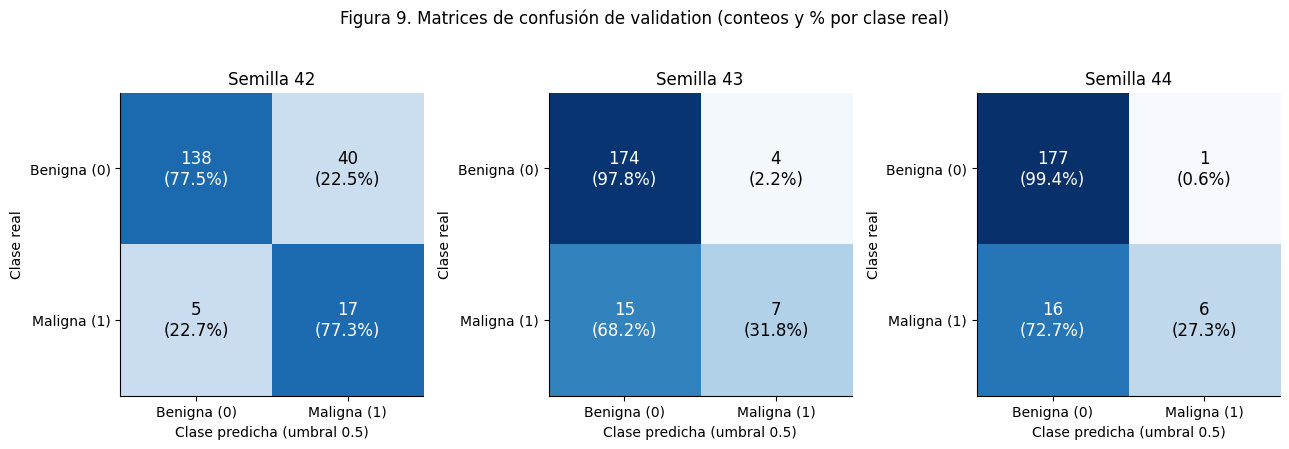

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, seed in zip(axes, SEEDS):
    matrix = CONFUSION[seed]
    assert matrix.tolist() == saved_metrics[seed]["confusion_matrix"]
    row_fraction = matrix / matrix.sum(axis=1, keepdims=True)

    ax.imshow(row_fraction, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, f"{matrix[i, j]}\n({row_fraction[i, j]:.1%})",
                ha="center", va="center", fontsize=12,
                color="white" if row_fraction[i, j] > 0.5 else "black",
            )
    ax.set_xticks([0, 1])
    ax.set_xticklabels([CLASS_NAMES[0], CLASS_NAMES[1]])
    ax.set_yticks([0, 1])
    ax.set_yticklabels([CLASS_NAMES[0], CLASS_NAMES[1]])
    ax.set_xlabel("Clase predicha (umbral 0.5)")
    ax.set_ylabel("Clase real")
    ax.set_title(f"Semilla {seed}")
    ax.grid(False)

fig.suptitle("Figura 9. Matrices de confusión de validation (conteos y % por clase real)", y=1.02)
fig.tight_layout()
save_figure(fig, "f9_matrices_confusion")
plt.show()

Se presentan los errores por semilla: conteos, tasas de error por clase real y mediana de la probabilidad asignada a las imágenes mal clasificadas (indica si los errores están cerca o lejos del umbral 0.5).

In [25]:
error_rows = []
for seed in SEEDS:
    sub = pred[pred["seed"] == seed]
    matrix = CONFUSION[seed]
    tn, fp, fn, tp = (int(v) for v in matrix.ravel())
    fp_probs = sub.loc[sub["outcome"] == "FP", "probability_malignant"]
    fn_probs = sub.loc[sub["outcome"] == "FN", "probability_malignant"]
    error_rows.append(
        {
            "seed": seed,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "tasa_falsos_positivos": fp / N_BENIGN,
            "tasa_falsos_negativos": fn / N_MALIGNANT,
            "sensibilidad": tp / (tp + fn),
            "especificidad": tn / (tn + fp),
            "mediana_prob_FP": float(fp_probs.median()) if len(fp_probs) else np.nan,
            "mediana_prob_FN": float(fn_probs.median()) if len(fn_probs) else np.nan,
        }
    )
error_summary = pd.DataFrame(error_rows)
save_table(error_summary, "t7_errores_por_semilla")
error_summary.round(4)

,seed,TN,FP,FN,TP,tasa_falsos_positivos,tasa_falsos_negativos,sensibilidad,especificidad,mediana_prob_FP,mediana_prob_FN
0,42,138,40,5,17,0.2247,0.2273,0.7727,0.7753,0.6920,0.2232
1,43,174,4,15,7,0.0225,0.6818,0.3182,0.9775,0.8129,0.0362
2,44,177,1,16,6,0.0056,0.7273,0.2727,0.9944,0.7645,0.0281


Ademas de la coincidencias entre semillas de las imágenes mal clasificadas, separadas por tipo de error: tamaño de cada conjunto, intersecciones por pares y entre las tres semillas, unión, índice de Jaccard (intersección / unión) y número de imágenes de la clase que no fueron mal clasificadas por ninguna semilla.

In [26]:
error_sets = {
    kind: {
        seed: set(pred.loc[(pred["seed"] == seed) & (pred["outcome"] == kind), "image_id"])
        for seed in SEEDS
    }
    for kind in ("FP", "FN")
}
CLASS_SIZE = {"FP": N_BENIGN, "FN": N_MALIGNANT}


def jaccard(sets):
    union = set.union(*sets)
    return len(set.intersection(*sets)) / len(union) if union else np.nan


overlap_rows = []
for kind, sets in error_sets.items():
    row = {"tipo_error": kind, "n_imagenes_de_la_clase": CLASS_SIZE[kind]}
    for seed in SEEDS:
        row[f"n_seed_{seed}"] = len(sets[seed])
    for a, b in pairs:
        row[f"interseccion_{a}_{b}"] = len(sets[a] & sets[b])
        row[f"jaccard_{a}_{b}"] = jaccard([sets[a], sets[b]])
    row["interseccion_3_semillas"] = len(set.intersection(*sets.values()))
    row["union_3_semillas"] = len(set.union(*sets.values()))
    row["jaccard_3_semillas"] = jaccard(list(sets.values()))
    row["sin_error_en_ninguna_semilla"] = CLASS_SIZE[kind] - row["union_3_semillas"]
    overlap_rows.append(row)
overlap_table = pd.DataFrame(overlap_rows)

combo_rows = []
for kind, sets in error_sets.items():
    total = 0
    for size in (1, 2, 3):
        for combo in itertools.combinations(SEEDS, size):
            inside = set.intersection(*[sets[s] for s in combo])
            outside = set.union(set(), *[sets[s] for s in SEEDS if s not in combo])
            exact = inside - outside
            total += len(exact)
            combo_rows.append(
                {"tipo_error": kind, "semillas": "+".join(str(s) for s in combo), "n_semillas": size, "n_imagenes": len(exact)}
            )
    assert total == len(set.union(*sets.values())), kind
combination_table = pd.DataFrame(combo_rows)

save_table(overlap_table, "t8_coincidencia_errores")
save_table(combination_table, "t8b_combinaciones_de_error")
display(overlap_table.round(4).T)
combination_table

,0,1
tipo_error,FP,FN
n_imagenes_de_la_clase,178,22
n_seed_42,40,5
n_seed_43,4,15
n_seed_44,1,16
interseccion_42_43,4,5
jaccard_42_43,0.1,0.3333
interseccion_42_44,1,4
jaccard_42_44,0.025,0.2353
interseccion_43_44,1,14


,tipo_error,semillas,n_semillas,n_imagenes
0,FP,42,1,36
1,FP,43,1,0
2,FP,44,1,0
3,FP,42+43,2,3
4,FP,42+44,2,0
5,FP,43+44,2,0
6,FP,42+43+44,3,1
7,FN,42,1,0
8,FN,43,1,0
9,FN,44,1,2


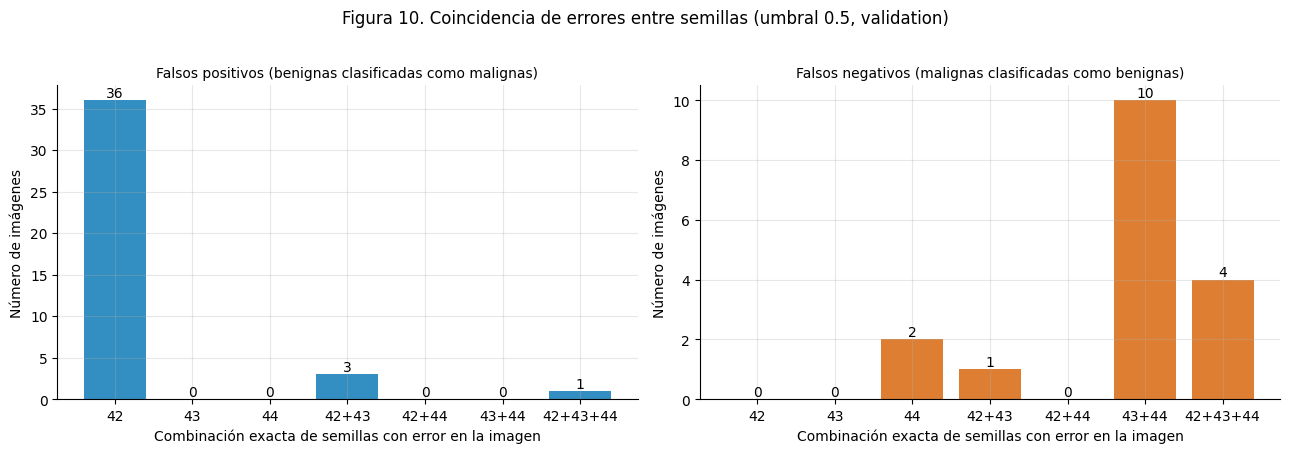

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
titles = {
    "FP": "Falsos positivos (benignas clasificadas como malignas)",
    "FN": "Falsos negativos (malignas clasificadas como benignas)",
}
for ax, kind in zip(axes, ("FP", "FN")):
    sub = combination_table[combination_table["tipo_error"] == kind].reset_index(drop=True)
    cls = 0 if kind == "FP" else 1
    bars = ax.bar(range(len(sub)), sub["n_imagenes"], color=CLASS_COLORS[cls], alpha=0.8)
    for bar, value in zip(bars, sub["n_imagenes"]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(int(value)), ha="center", va="bottom", fontsize=10)
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(sub["semillas"])
    ax.set_xlabel("Combinación exacta de semillas con error en la imagen")
    ax.set_ylabel("Número de imágenes")
    ax.set_title(titles[kind], fontsize=10)
fig.suptitle("Figura 10. Coincidencia de errores entre semillas (umbral 0.5, validation)", y=1.02)
fig.tight_layout()
save_figure(fig, "f10_coincidencia_errores")
plt.show()

Listado de las imágenes mal clasificadas por al menos una semilla, con la probabilidad asignada y el resultado (TN/FP/FN/TP) en cada semilla. Permite trazar cada error por `image_id`. Se muestran todas las malignas con algún error y las benignas con error en dos o más semillas; el archivo exportado contiene la lista completa.

In [28]:
outcome_wide = pred.pivot(index="image_id", columns="seed", values="outcome")

image_errors = pd.concat(
    [
        labels.rename("y_true"),
        prob_wide.add_prefix("prob_seed_"),
        outcome_wide.add_prefix("resultado_seed_"),
    ],
    axis=1,
)
image_errors["n_semillas_con_error"] = outcome_wide.isin(["FP", "FN"]).sum(axis=1)
image_errors = (
    image_errors[image_errors["n_semillas_con_error"] > 0]
    .sort_values(["y_true", "n_semillas_con_error"], ascending=[False, False])
    .reset_index()
)

save_table(image_errors, "t8c_imagenes_mal_clasificadas")

shown = image_errors[(image_errors["y_true"] == 1) | (image_errors["n_semillas_con_error"] >= 2)]
print(f"Imágenes mal clasificadas por al menos una semilla: {len(image_errors)} "
      f"({int((image_errors['y_true'] == 0).sum())} benignas, {int((image_errors['y_true'] == 1).sum())} malignas)")
shown.round(4)

Imágenes mal clasificadas por al menos una semilla: 57 (40 benignas, 17 malignas)


,image_id,y_true,prob_seed_42,prob_seed_43,prob_seed_44,resultado_seed_42,resultado_seed_43,resultado_seed_44,n_semillas_con_error
0,814,1,0.0627,0.0151,0.1094,FN,FN,FN,3
1,1436,1,0.3235,0.0041,0.0007,FN,FN,FN,3
2,1177,1,0.2232,0.0030,0.0117,FN,FN,FN,3
3,1443,1,0.3712,0.0921,0.1424,FN,FN,FN,3
4,1090,1,0.7693,0.0237,0.0190,TP,FN,FN,2
5,413,1,0.1933,0.4161,0.7163,FN,FN,TP,2
6,895,1,0.8392,0.0504,0.0472,TP,FN,FN,2
7,215,1,0.9821,0.0145,0.0234,TP,FN,FN,2
8,920,1,0.6092,0.0046,0.0023,TP,FN,FN,2
9,1445,1,0.7153,0.0020,0.0148,TP,FN,FN,2


## 8. Síntesis diagnóstica

La tabla final se construye **a partir de los resultados calculados en este notebook**: cada fila incluye una comprobación automática (`check`) del enunciado descriptivo. Si la comprobación se cumple, el hallazgo se marca como **[Comprobado]**; si no, como **[No confirmado]**. Las explicaciones se marcan como **[Hipótesis pendiente]**: son conjeturas que este notebook no contrasta. Las implicaciones son **condicionales** (solo aplican si la hipótesis se confirma) y no constituyen recomendaciones de técnicas.

In [29]:
baseline = baseline_metrics.set_index("seed")
evo = evolution.set_index("seed")
err = error_summary.set_index("seed")
crit = stopping_summary.set_index("seed")
pr = pr_table.set_index("seed")
sep = separation.set_index("seed")
ov = overlap_table.set_index("tipo_error")

auc_range = float(baseline["roc_auc"].max() - baseline["roc_auc"].min())
sens_range = float(baseline["sensitivity"].max() - baseline["sensitivity"].min())
spec_range = float(baseline["specificity"].max() - baseline["specificity"].min())

fp_more = [s for s in SEEDS if err.loc[s, "FP"] > err.loc[s, "FN"]]
fn_more = [s for s in SEEDS if err.loc[s, "FN"] > err.loc[s, "FP"]]

r6_ap_ci = selected_r6["metrics_validation"]["average_precision"]
sensitivity_step = 1 / N_MALIGNANT

findings = []

findings.append(
    {
        "check": sens_range > auc_range,
        "hallazgo": (
            f"El ROC-AUC varía poco entre semillas (rango {auc_range:.3f}), mientras que la sensibilidad con umbral 0.5 "
            f"varía mucho más (rango {sens_range:.3f}) y la especificidad también (rango {spec_range:.3f})."
        ),
        "evidencia": (
            f"ROC-AUC: {by_seed(baseline['roc_auc'])}; sensibilidad: {by_seed(baseline['sensitivity'])}; "
            f"especificidad: {by_seed(baseline['specificity'])} (T0, T7)."
        ),
        "explicacion": (
            "La regla de decisión con umbral 0.5 podría no ser estable entre trayectorias de entrenamiento "
            "(posible dependencia de la escala o calibración de las probabilidades, que este notebook no evalúa). "
            f"Con {N_MALIGNANT} malignas, cada FN modifica la sensibilidad en {sensitivity_step:.3f}."
        ),
        "implicacion": (
            "Si se confirma, comparar configuraciones con métricas independientes del umbral (AP, ROC-AUC) y reportar "
            "sensibilidad/especificidad a 0.5 como punto de operación fijo. Cualquier estudio de umbral requiere una decisión explícita posterior."
        ),
    }
)

findings.append(
    {
        "check": len(fp_more) > 0 and len(fn_more) > 0,
        "hallazgo": (
            f"El tipo de error predominante cambia entre semillas: FP > FN en las semillas {fp_more or 'ninguna'} "
            f"y FN > FP en las semillas {fn_more or 'ninguna'}."
        ),
        "evidencia": (
            f"FP por semilla: {by_seed(err['FP'], 0)}; FN por semilla: {by_seed(err['FN'], 0)}; "
            f"mediana de probabilidad de los FP: {by_seed(err['mediana_prob_FP'])}; de los FN: {by_seed(err['mediana_prob_FN'])} (T7)."
        ),
        "explicacion": (
            "El sesgo del modelo hacia una u otra clase en 0.5 podría depender de la trayectoria y de la época en que cae el checkpoint; "
            "los pesos de clase (0.56 / 4.60) podrían intervenir. No se ha contrastado."
        ),
        "implicacion": (
            "Si se confirma, conviene examinar si el punto de operación a 0.5 depende del criterio de checkpoint antes de atribuir "
            "diferencias de sensibilidad o especificidad a cambios de configuración."
        ),
    }
)

jaccard_fp, jaccard_fn = float(ov.loc["FP", "jaccard_3_semillas"]), float(ov.loc["FN", "jaccard_3_semillas"])
findings.append(
    {
        "check": jaccard_fp < 0.5 and jaccard_fn < 0.5,
        "hallazgo": (
            f"Las imágenes mal clasificadas coinciden poco entre semillas: FP comunes a las 3 semillas "
            f"{int(ov.loc['FP', 'interseccion_3_semillas'])} de {int(ov.loc['FP', 'union_3_semillas'])} distintos "
            f"(Jaccard {jaccard_fp:.2f}); FN comunes {int(ov.loc['FN', 'interseccion_3_semillas'])} de "
            f"{int(ov.loc['FN', 'union_3_semillas'])} distintos (Jaccard {jaccard_fn:.2f})."
        ),
        "evidencia": "T8, T8b, T8c y Figura 10.",
        "explicacion": (
            "Parte de los errores podría deberse a la variabilidad de la inicialización y del orden de los datos, y no a imágenes "
            "intrínsecamente difíciles; los errores comunes sí podrían corresponder a casos difíciles. No se ha contrastado, y no puede "
            "separarse del efecto de imágenes correlacionadas por paciente (sin identificadores)."
        ),
        "implicacion": (
            "Si se confirma, toda comparación en R7 debe usar las tres semillas y reportar su variabilidad; una mejora observada "
            "en una sola semilla no es evidencia suficiente."
        ),
    }
)

differ = [s for s in SEEDS if not bool(crit.loc[s, "criterios_coinciden_en_la_misma_epoca"])]
findings.append(
    {
        "check": len(differ) > 0,
        "hallazgo": (
            "El criterio de parada (mínimo de val_loss) y el de checkpoint (máximo de val_roc_auc) señalan épocas distintas "
            f"en las semillas {differ or 'ninguna'}."
        ),
        "evidencia": (
            f"Época del mínimo de val_loss: {by_seed(crit['epoca_min_val_loss'], 0)}; época del checkpoint: "
            f"{by_seed(crit['epoca_checkpoint_max_roc_auc'], 0)}; val_loss en el checkpoint: {by_seed(evo['val_loss_checkpoint'])} "
            f"frente al mínimo {by_seed(evo['val_loss_min'])} (T2b, T3, T4, T4b, Figura 3)."
        ),
        "explicacion": (
            "Los dos criterios miden aspectos distintos (calibración/pérdida frente a ranking), por lo que no tienen por qué coincidir; "
            "el checkpoint por AUC puede caer en épocas con val_loss alta. Si ello afecta el desempeño reportado no se ha contrastado."
        ),
        "implicacion": (
            "Si se confirma, documentarlo como fuente de variabilidad. Cualquier cambio de criterio de parada o de checkpoint sería "
            "una intervención de R7 que debe justificarse; no se modifica en esta fase."
        ),
    }
)

train_down = all(evo.loc[s, "train_loss_final"] < evo.loc[s, "train_loss_en_min_val_loss"] for s in SEEDS)
val_up = all(evo.loc[s, "val_loss_final"] > evo.loc[s, "val_loss_min"] for s in SEEDS)
findings.append(
    {
        "check": train_down and val_up,
        "hallazgo": (
            "Al final del entrenamiento train_loss es menor que en la época del mínimo de val_loss, mientras que val_loss final es mayor "
            "que su mínimo, en las tres semillas."
        ),
        "evidencia": (
            f"train_loss final: {by_seed(evo['train_loss_final'])}; val_loss final: {by_seed(evo['val_loss_final'])}; "
            f"val_loss mínima: {by_seed(evo['val_loss_min'])}; val_unweighted_loss final: {by_seed(evo['val_unweighted_final'])} "
            f"(mínima {by_seed(evo['val_unweighted_min'])}) (T3, Figuras 1 y 2)."
        ),
        "explicacion": (
            "Hipótesis no excluyentes y pendientes: sobreajuste al conjunto de entrenamiento; efecto del peso de clase de la categoría maligna "
            f"sobre una pérdida calculada con {N_MALIGNANT} positivos; ruido de la pérdida de validation. Este notebook no discrimina entre ellas."
        ),
        "implicacion": (
            "Si se identifica el mecanismo, la técnica de R7 debería dirigirse a ese mecanismo; antes de elegir regularización u otras técnicas, "
            "contrastar qué hipótesis explica el patrón (por ejemplo, comparando pérdida ponderada y sin ponderar con las métricas de ranking en las mismas épocas)."
        ),
    }
)

ap_gap = {s: float(evo.loc[s, "val_ap_max"] - evo.loc[s, "val_ap_checkpoint"]) for s in SEEDS}
findings.append(
    {
        "check": any(gap > 0 for gap in ap_gap.values()),
        "hallazgo": (
            "La época del checkpoint por ROC-AUC no es la de máximo AP en algunas semillas: "
            f"AP máximo − AP en el checkpoint = {by_seed(ap_gap)}."
        ),
        "evidencia": (
            f"AP en el checkpoint: {by_seed(evo['val_ap_checkpoint'])}; AP máximo: {by_seed(evo['val_ap_max'])} "
            f"en las épocas {by_seed(evo['epoca_max_val_ap'], 0)} (T3, T4)."
        ),
        "explicacion": (
            "ROC-AUC y AP ponderan de forma distinta el orden de las imágenes (AP es más sensible a la parte alta del ranking cuando hay pocos positivos); "
            "R6 seleccionó la configuración por AP, pero el checkpoint de R4 se elige por ROC-AUC. Las diferencias pueden estar dentro del ruido; no se ha contrastado."
        ),
        "implicacion": (
            "Si se confirma, tener presente el desalineamiento entre la métrica de selección de la configuración (AP) y la del checkpoint (ROC-AUC) "
            "al interpretar mejoras; su eventual modificación no se realiza aquí."
        ),
    }
)

epochs_run_by_seed = {s: run_configs[s]["epochs_run"] for s in SEEDS}
epochs_run_text = by_seed(epochs_run_by_seed, 0)
findings.append(
    {
        "check": len(set(epochs_run_by_seed.values())) > 1,
        "hallazgo": (
            f"La duración del entrenamiento difiere entre semillas ({epochs_run_text} épocas) "
            "aunque el protocolo es idéntico."
        ),
        "evidencia": (
            f"Época de la última mejora de val_loss > min_delta: {by_seed(crit['epoca_ultima_mejora_early_stopping'], 0)}; "
            f"fin del entrenamiento: {by_seed(crit['epoca_fin_entrenamiento'], 0)} (T2, T2b, T2c, Figura 3)."
        ),
        "explicacion": (
            "El early stopping sobre una pérdida de validation ponderada con 22 positivos podría ser un criterio ruidoso que produce trayectorias de "
            "longitud distinta. No se ha contrastado."
        ),
        "implicacion": (
            "Si se confirma, la longitud del entrenamiento debe considerarse una fuente de variabilidad al comparar configuraciones de R7."
        ),
    }
)

ap_over_prevalence = pr["ap_sobre_prevalencia"]
findings.append(
    {
        "check": bool((pr["average_precision"] > PREVALENCE).all()),
        "hallazgo": (
            f"El AP de cada semilla supera la prevalencia ({PREVALENCE:.2f}) pero deja margen de mejora: AP/prevalencia = {by_seed(ap_over_prevalence, 2)}."
        ),
        "evidencia": (
            f"AP: {by_seed(pr['average_precision'])}; precisión máxima con exhaustividad ≥ 0.7: "
            f"{by_seed(pr['precision_max_con_recall_>=_0.7'])}; coeficiente de solapamiento entre clases: {by_seed(sep['coeficiente_solapamiento'])} "
            "(T5b, T6, Figuras 4 a 8)."
        ),
        "explicacion": (
            "La superposición de las distribuciones de ambas clases podría limitar la precisión a exhaustividad alta; no se ha determinado su origen "
            "(señal insuficiente, ruido de etiquetas, número de malignas en entrenamiento: 87)."
        ),
        "implicacion": (
            "Si se confirma, la mejora de R7 debería evaluarse sobre AP/curva PR y no solo sobre ROC-AUC o exactitud."
        ),
    }
)

findings.append(
    {
        "check": int(labels.sum()) == N_MALIGNANT,
        "hallazgo": (
            f"Limitación del diseño: validation contiene solo {N_MALIGNANT} imágenes malignas y el manifiesto no incluye identificadores de paciente."
        ),
        "evidencia": (
            f"IC 95 % bootstrap del AP en R6: [{r6_ap_ci['ci95_lower']:.3f}, {r6_ap_ci['ci95_upper']:.3f}]; "
            f"un FN equivale a {sensitivity_step:.3f} de sensibilidad (T0b, T7; configs/splits/README.md)."
        ),
        "explicacion": "No aplica: es una propiedad de los datos disponibles, no una hipótesis.",
        "implicacion": (
            "Las diferencias entre configuraciones deben interpretarse con la variabilidad entre semillas y los intervalos de incertidumbre; "
            "la independencia entre pacientes no puede verificarse."
        ),
    }
)

synthesis = pd.DataFrame(
    [
        {
            "Hallazgo observado": ("[Comprobado] " if f["check"] else "[No confirmado] ") + f["hallazgo"],
            "Evidencia": f["evidencia"],
            "Posible explicación": (
                f["explicacion"] if f["explicacion"].startswith("No aplica") else "[Hipótesis pendiente] " + f["explicacion"]
            ),
            "Implicación para R7": "[Condicional] " + f["implicacion"],
        }
        for f in findings
    ]
)


def to_markdown_table(df: pd.DataFrame) -> str:
    header = "| " + " | ".join(df.columns) + " |"
    separator = "|" + "|".join(["---"] * len(df.columns)) + "|"
    body = [
        "| " + " | ".join(str(value).replace("|", "\\|").replace("\n", " ") for value in row) + " |"
        for row in df.itertuples(index=False)
    ]
    return "\n".join([header, separator, *body])


save_table(synthesis, "t9_sintesis_diagnostica")
display(Markdown(to_markdown_table(synthesis)))

| Hallazgo observado | Evidencia | Posible explicación | Implicación para R7 |
|---|---|---|---|
| [Comprobado] El ROC-AUC varía poco entre semillas (rango 0.070), mientras que la sensibilidad con umbral 0.5 varía mucho más (rango 0.500) y la especificidad también (rango 0.219). | ROC-AUC: 42: 0.885 · 43: 0.829 · 44: 0.816; sensibilidad: 42: 0.773 · 43: 0.318 · 44: 0.273; especificidad: 42: 0.775 · 43: 0.978 · 44: 0.994 (T0, T7). | [Hipótesis pendiente] La regla de decisión con umbral 0.5 podría no ser estable entre trayectorias de entrenamiento (posible dependencia de la escala o calibración de las probabilidades, que este notebook no evalúa). Con 22 malignas, cada FN modifica la sensibilidad en 0.045. | [Condicional] Si se confirma, comparar configuraciones con métricas independientes del umbral (AP, ROC-AUC) y reportar sensibilidad/especificidad a 0.5 como punto de operación fijo. Cualquier estudio de umbral requiere una decisión explícita posterior. |
| [Comprobado] El tipo de error predominante cambia entre semillas: FP > FN en las semillas [42] y FN > FP en las semillas [43, 44]. | FP por semilla: 42: 40 · 43: 4 · 44: 1; FN por semilla: 42: 5 · 43: 15 · 44: 16; mediana de probabilidad de los FP: 42: 0.692 · 43: 0.813 · 44: 0.764; de los FN: 42: 0.223 · 43: 0.036 · 44: 0.028 (T7). | [Hipótesis pendiente] El sesgo del modelo hacia una u otra clase en 0.5 podría depender de la trayectoria y de la época en que cae el checkpoint; los pesos de clase (0.56 / 4.60) podrían intervenir. No se ha contrastado. | [Condicional] Si se confirma, conviene examinar si el punto de operación a 0.5 depende del criterio de checkpoint antes de atribuir diferencias de sensibilidad o especificidad a cambios de configuración. |
| [Comprobado] Las imágenes mal clasificadas coinciden poco entre semillas: FP comunes a las 3 semillas 1 de 40 distintos (Jaccard 0.03); FN comunes 4 de 17 distintos (Jaccard 0.24). | T8, T8b, T8c y Figura 10. | [Hipótesis pendiente] Parte de los errores podría deberse a la variabilidad de la inicialización y del orden de los datos, y no a imágenes intrínsecamente difíciles; los errores comunes sí podrían corresponder a casos difíciles. No se ha contrastado, y no puede separarse del efecto de imágenes correlacionadas por paciente (sin identificadores). | [Condicional] Si se confirma, toda comparación en R7 debe usar las tres semillas y reportar su variabilidad; una mejora observada en una sola semilla no es evidencia suficiente. |
| [Comprobado] El criterio de parada (mínimo de val_loss) y el de checkpoint (máximo de val_roc_auc) señalan épocas distintas en las semillas [43, 44]. | Época del mínimo de val_loss: 42: 8 · 43: 3 · 44: 3; época del checkpoint: 42: 8 · 43: 7 · 44: 7; val_loss en el checkpoint: 42: 0.432 · 43: 1.142 · 44: 1.248 frente al mínimo 42: 0.432 · 43: 0.593 · 44: 0.586 (T2b, T3, T4, T4b, Figura 3). | [Hipótesis pendiente] Los dos criterios miden aspectos distintos (calibración/pérdida frente a ranking), por lo que no tienen por qué coincidir; el checkpoint por AUC puede caer en épocas con val_loss alta. Si ello afecta el desempeño reportado no se ha contrastado. | [Condicional] Si se confirma, documentarlo como fuente de variabilidad. Cualquier cambio de criterio de parada o de checkpoint sería una intervención de R7 que debe justificarse; no se modifica en esta fase. |
| [Comprobado] Al final del entrenamiento train_loss es menor que en la época del mínimo de val_loss, mientras que val_loss final es mayor que su mínimo, en las tres semillas. | train_loss final: 42: 0.054 · 43: 0.140 · 44: 0.109; val_loss final: 42: 1.700 · 43: 0.723 · 44: 0.989; val_loss mínima: 42: 0.432 · 43: 0.593 · 44: 0.586; val_unweighted_loss final: 42: 0.434 · 43: 0.406 · 44: 0.322 (mínima 42: 0.245 · 43: 0.322 · 44: 0.286) (T3, Figuras 1 y 2). | [Hipótesis pendiente] Hipótesis no excluyentes y pendientes: sobreajuste al conjunto de entrenamiento; efecto del peso de clase de la categoría maligna sobre una pérdida calculada con 22 positivos; ruido de la pérdida de validation. Este notebook no discrimina entre ellas. | [Condicional] Si se identifica el mecanismo, la técnica de R7 debería dirigirse a ese mecanismo; antes de elegir regularización u otras técnicas, contrastar qué hipótesis explica el patrón (por ejemplo, comparando pérdida ponderada y sin ponderar con las métricas de ranking en las mismas épocas). |
| [Comprobado] La época del checkpoint por ROC-AUC no es la de máximo AP en algunas semillas: AP máximo − AP en el checkpoint = 42: 0.007 · 43: 0.000 · 44: 0.030. | AP en el checkpoint: 42: 0.590 · 43: 0.530 · 44: 0.505; AP máximo: 42: 0.597 · 43: 0.530 · 44: 0.535 en las épocas 42: 10 · 43: 7 · 44: 8 (T3, T4). | [Hipótesis pendiente] ROC-AUC y AP ponderan de forma distinta el orden de las imágenes (AP es más sensible a la parte alta del ranking cuando hay pocos positivos); R6 seleccionó la configuración por AP, pero el checkpoint de R4 se elige por ROC-AUC. Las diferencias pueden estar dentro del ruido; no se ha contrastado. | [Condicional] Si se confirma, tener presente el desalineamiento entre la métrica de selección de la configuración (AP) y la del checkpoint (ROC-AUC) al interpretar mejoras; su eventual modificación no se realiza aquí. |
| [Comprobado] La duración del entrenamiento difiere entre semillas (42: 13 · 43: 8 · 44: 8 épocas) aunque el protocolo es idéntico. | Época de la última mejora de val_loss > min_delta: 42: 8 · 43: 3 · 44: 3; fin del entrenamiento: 42: 13 · 43: 8 · 44: 8 (T2, T2b, T2c, Figura 3). | [Hipótesis pendiente] El early stopping sobre una pérdida de validation ponderada con 22 positivos podría ser un criterio ruidoso que produce trayectorias de longitud distinta. No se ha contrastado. | [Condicional] Si se confirma, la longitud del entrenamiento debe considerarse una fuente de variabilidad al comparar configuraciones de R7. |
| [Comprobado] El AP de cada semilla supera la prevalencia (0.11) pero deja margen de mejora: AP/prevalencia = 42: 5.36 · 43: 4.81 · 44: 4.59. | AP: 42: 0.590 · 43: 0.530 · 44: 0.505; precisión máxima con exhaustividad ≥ 0.7: 42: 0.485 · 43: 0.302 · 44: 0.254; coeficiente de solapamiento entre clases: 42: 0.259 · 43: 0.420 · 44: 0.544 (T5b, T6, Figuras 4 a 8). | [Hipótesis pendiente] La superposición de las distribuciones de ambas clases podría limitar la precisión a exhaustividad alta; no se ha determinado su origen (señal insuficiente, ruido de etiquetas, número de malignas en entrenamiento: 87). | [Condicional] Si se confirma, la mejora de R7 debería evaluarse sobre AP/curva PR y no solo sobre ROC-AUC o exactitud. |
| [Comprobado] Limitación del diseño: validation contiene solo 22 imágenes malignas y el manifiesto no incluye identificadores de paciente. | IC 95 % bootstrap del AP en R6: [0.381, 0.700]; un FN equivale a 0.045 de sensibilidad (T0b, T7; configs/splits/README.md). | No aplica: es una propiedad de los datos disponibles, no una hipótesis. | [Condicional] Las diferencias entre configuraciones deben interpretarse con la variabilidad entre semillas y los intervalos de incertidumbre; la independencia entre pacientes no puede verificarse. |

## 9. Exportación y limitaciones

Se escribe el manifiesto de la ejecución con las fuentes leídas (ruta y tamaño), las salidas generadas y las versiones del entorno. Los checkpoints `best_auc.pth` se registran solo por su existencia y tamaño; no se cargan ni se hashean.

**Limitaciones del diagnóstico**

1. Solo existen probabilidades por imagen del checkpoint de cada semilla; no hay predicciones por época para las semillas 43 y 44, y no se generan nuevas.
2. Validation tiene 22 malignas: las métricas y las coincidencias de errores son descriptivas, con alta incertidumbre.
3. No hay identificadores de paciente: no puede verificarse la independencia entre imágenes ni entre particiones.
4. `train_loss` (modo `train`, promedio durante la época) y `val_loss` (modo `eval`, al final de la época) no son estrictamente comparables.
5. Tres semillas describen la variabilidad entre inicializaciones, no permiten estimarla con precisión.
6. Los hallazgos describen validation; no se evaluó `test`.

In [30]:
sources_manifest = [
    {
        "path": path.relative_to(PROJECT_ROOT).as_posix(),
        "bytes": path.stat().st_size,
    }
    for path in SOURCE_PATHS
]
checkpoints_not_loaded = [
    {"path": (run_dir(seed) / CHECKPOINT_FILE).relative_to(PROJECT_ROOT).as_posix(), "bytes": (run_dir(seed) / CHECKPOINT_FILE).stat().st_size}
    for seed in SEEDS
]

# Se registra también el propio manifiesto de salida
manifest_path = _checked_output_path(OUTPUT_DIR / f"{FILE_PREFIX}_manifest.json")
manifest_relative = manifest_path.relative_to(PROJECT_ROOT.resolve()).as_posix()
if manifest_relative not in OUTPUT_REGISTRY:
    OUTPUT_REGISTRY.append(manifest_relative)

run_manifest = {
    "notebook": "notebooks/R7_optimizacion/00_diagnostico_baseline_r7.ipynb",
    "purpose": "Diagnóstico de la configuración basal ConvNeXt-Tiny-A (R7, Fase 0)",
    "scope": {
        "architecture": ARCH,
        "condition": CONDITION,
        "seeds": SEEDS,
        "evaluation_split": "validation",
        "n_validation": N_VALIDATION,
        "n_malignant_validation": N_MALIGNANT,
        "threshold": THRESHOLD,
        "test_used": False,
        "new_training": False,
        "new_inference": False,
        "modifies_r4_r5_r6": False,
    },
    "sources": sources_manifest,
    "checkpoints_not_loaded": checkpoints_not_loaded,
    "outputs": sorted(OUTPUT_REGISTRY),
    "environment": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": matplotlib.__version__,
        "scikit-learn": sklearn.__version__,
    },
}

with open(manifest_path, "w", encoding="utf-8") as handle:
    json.dump(run_manifest, handle, indent=2, ensure_ascii=False)

print(f"Archivos de salida registrados: {len(OUTPUT_REGISTRY)}")
for relative in sorted(OUTPUT_REGISTRY):
    print(" -", relative)

Archivos de salida registrados: 30
 - results/classification/r7_optimizacion/diagnostico_baseline/figures/r7_diag_f10_coincidencia_errores.png
 - results/classification/r7_optimizacion/diagnostico_baseline/figures/r7_diag_f1_curvas_perdida.png
 - results/classification/r7_optimizacion/diagnostico_baseline/figures/r7_diag_f2_curvas_auc_ap.png
 - results/classification/r7_optimizacion/diagnostico_baseline/figures/r7_diag_f3_criterios_parada_checkpoint.png
 - results/classification/r7_optimizacion/diagnostico_baseline/figures/r7_diag_f4_histogramas_probabilidad.png
 - results/classification/r7_optimizacion/diagnostico_baseline/figures/r7_diag_f5_cajas_probabilidad.png
 - results/classification/r7_optimizacion/diagnostico_baseline/figures/r7_diag_f6_ecdf_probabilidad.png
 - results/classification/r7_optimizacion/diagnostico_baseline/figures/r7_diag_f7_dispersion_entre_semillas.png
 - results/classification/r7_optimizacion/diagnostico_baseline/figures/r7_diag_f8_curvas_precision_recall.png
